<div style="border: 10px solid black; background-color:#ffd700; color:black; text-align:left; padding: 30px; font-size:40px; font-family:Verdana, sans-serif;">
<b>1. Importing Libraries</b>
</div>

In [1]:
import numpy as np
import pandas as pd
import os
import warnings
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.impute import KNNImputer
from scipy.stats.mstats import winsorize
from sklearn.model_selection import train_test_split
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from xgboost import XGBClassifier
from sklearn.preprocessing import StandardScaler

<div style="border: 10px solid black; background-color:#ffd700; color:black; text-align:left; padding: 30px; font-size:40px; font-family:Verdana, sans-serif;">
<b>2. Data Importing</b>
</div>

In [2]:
def load_csv(file_path):
    """Loads a CSV file into a DataFrame"""
    try:
        if not os.path.exists(file_path):
            raise FileNotFoundError(f"Error: File '{file_path}' not found!")

        df = pd.read_csv(file_path)

        print(f"✅ CSV file! Shape: {df.shape}")

        return df
    except FileNotFoundError as fnf_error:
        print(fnf_error)
    except pd.errors.EmptyDataError:
        print("Error: The CSV file is empty!")
    except pd.errors.ParserError:
        print("Error: CSV parsing issue. Check the file format.")
    except Exception as e:
        print(f"Unexpected error: {e}")

    return None  

In [3]:
df = load_csv("/kaggle/input/stroke-risk-prediction-dataset/stroke_risk_dataset.csv")

✅ CSV file! Shape: (70000, 18)


In [4]:
df.head()

,Chest Pain,Shortness of Breath,Irregular Heartbeat,Fatigue & Weakness,Dizziness,Swelling (Edema),Pain in Neck/Jaw/Shoulder/Back,Excessive Sweating,Persistent Cough,Nausea/Vomiting,High Blood Pressure,Chest Discomfort (Activity),Cold Hands/Feet,Snoring/Sleep Apnea,Anxiety/Feeling of Doom,Age,Stroke Risk (%),At Risk (Binary)
0,0,1,1,1,0,0,0,1,1,1,0,1,1,0,0,54,58.0,1
1,0,0,1,0,0,1,0,0,0,0,1,0,1,1,0,49,40.5,0
2,1,0,0,1,1,1,0,0,1,0,0,0,0,1,0,62,52.0,1
3,1,0,1,1,0,1,1,1,1,1,1,0,0,0,0,48,60.0,1
4,0,0,1,0,0,1,0,1,0,1,1,0,0,1,1,61,56.5,1


In [5]:
df.columns

Index(['Chest Pain', 'Shortness of Breath', 'Irregular Heartbeat',
       'Fatigue & Weakness', 'Dizziness', 'Swelling (Edema)',
       'Pain in Neck/Jaw/Shoulder/Back', 'Excessive Sweating',
       'Persistent Cough', 'Nausea/Vomiting', 'High Blood Pressure',
       'Chest Discomfort (Activity)', 'Cold Hands/Feet', 'Snoring/Sleep Apnea',
       'Anxiety/Feeling of Doom', 'Age', 'Stroke Risk (%)',
       'At Risk (Binary)'],
      dtype='object')

In [6]:
def get_basic_info(df):
    """Get basic information about the dataset"""
    print(f"🔹 Number of Rows: {df.shape[0]}")
    print(f"🔹 Number of Columns: {df.shape[1]}")
    print(f"🔹 Columns: {df.columns.tolist()}")
    print(f"🔹 Column Data Types: {df.dtypes}")
    print(f"🔹 Missing Values: {df.isnull().sum().sum()}")
    print(f"🔹 Missing Values (Per Column) : {df.isnull().sum()}")
    print(f"🔹 Missing Values (Per Column Percentage) : {(df.isnull().mean() * 100)}")
    print(f"🔹 Unique Values: {df.nunique()}")

In [7]:
get_basic_info(df)

🔹 Number of Rows: 70000
🔹 Number of Columns: 18
🔹 Columns: ['Chest Pain', 'Shortness of Breath', 'Irregular Heartbeat', 'Fatigue & Weakness', 'Dizziness', 'Swelling (Edema)', 'Pain in Neck/Jaw/Shoulder/Back', 'Excessive Sweating', 'Persistent Cough', 'Nausea/Vomiting', 'High Blood Pressure', 'Chest Discomfort (Activity)', 'Cold Hands/Feet', 'Snoring/Sleep Apnea', 'Anxiety/Feeling of Doom', 'Age', 'Stroke Risk (%)', 'At Risk (Binary)']
🔹 Column Data Types: Chest Pain                          int64
Shortness of Breath                 int64
Irregular Heartbeat                 int64
Fatigue & Weakness                  int64
Dizziness                           int64
Swelling (Edema)                    int64
Pain in Neck/Jaw/Shoulder/Back      int64
Excessive Sweating                  int64
Persistent Cough                    int64
Nausea/Vomiting                     int64
High Blood Pressure                 int64
Chest Discomfort (Activity)         int64
Cold Hands/Feet                     

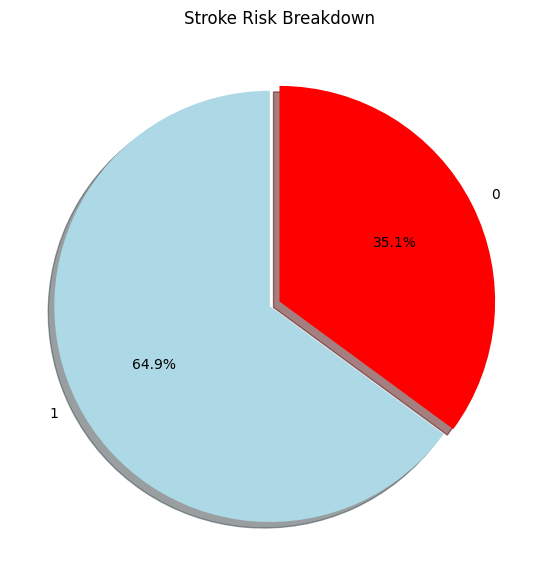

In [8]:
labels = df['At Risk (Binary)'].value_counts(sort=True).index
sizes = df['At Risk (Binary)'].value_counts(sort=True)

colors = ["lightblue", "red"]
explode = (0.05, 0)

plt.figure(figsize=(7, 7))
plt.pie(sizes[:2], explode=explode, labels=labels[:2], colors=colors, autopct='%1.1f%%', shadow=True, startangle=90)

plt.title('Stroke Risk Breakdown')
plt.show()


**Preprocessing Steps**

In [9]:
# Check for class imbalance
df['At Risk (Binary)'].value_counts()/len(df)

At Risk (Binary)
1    0.6492
0    0.3508
Name: count, dtype: float64

In [10]:
# Check for duplicates  --> ~0.015%
print("Duplicates:", df.duplicated().sum()/len(df))
df.drop_duplicates(inplace=True)

Duplicates: 0.014585714285714285


<div style="border: 10px solid black; background-color:#ffd700; color:black; text-align:left; padding: 30px; font-size:40px; font-family:Verdana, sans-serif;">
<b>3. Handling Missing Values</b>
</div>

In [11]:
# Missing values  --> no missing values
print("Missing Values:\n", df.isnull().sum())

Missing Values:
 Chest Pain                        0
Shortness of Breath               0
Irregular Heartbeat               0
Fatigue & Weakness                0
Dizziness                         0
Swelling (Edema)                  0
Pain in Neck/Jaw/Shoulder/Back    0
Excessive Sweating                0
Persistent Cough                  0
Nausea/Vomiting                   0
High Blood Pressure               0
Chest Discomfort (Activity)       0
Cold Hands/Feet                   0
Snoring/Sleep Apnea               0
Anxiety/Feeling of Doom           0
Age                               0
Stroke Risk (%)                   0
At Risk (Binary)                  0
dtype: int64


In [12]:
def plot_missing_heatmap(df):
    """Plot a heatmap to visualize missing values in the dataset."""
    missing_values = df.isnull().sum()
    missing_values = missing_values[missing_values > 0].sort_values(ascending=False)

    if missing_values.empty:
        print("✅ No missing values to plot.")
        return
    
    plt.figure(figsize=(10, 6))
    sns.heatmap(df.isnull(), cmap="viridis", cbar=False, yticklabels=False)
    plt.title("Missing Data Heatmap")
    plt.show()

In [13]:
def plot_missing_bar(df):
    """Plot a bar chart showing the count of missing values per column."""
    missing_values = df.isnull().sum()
    missing_values = missing_values[missing_values > 0].sort_values(ascending=False)

    if missing_values.empty:
        print("✅ No missing values to plot.")
        return

    plt.figure(figsize=(12, 6))
    sns.barplot(x=missing_values.index, y=missing_values.values, palette="magma")
    plt.xticks(rotation=90)
    plt.title("Missing Values Count per Column")
    plt.ylabel("Count")
    plt.show()

In [14]:
def plot_missing_pie(df):
    """Plot a pie chart showing the percentage of missing values per column."""
    missing_percent = (df.isnull().sum() / len(df)) * 100
    missing_percent = missing_percent[missing_percent > 0]

    if missing_percent.empty:
        print("✅ No missing values to plot.")
        return

    plt.figure(figsize=(8, 8))
    plt.pie(missing_percent, labels=missing_percent.index, autopct="%1.1f%%", colors=sns.color_palette("pastel"))
    plt.title("Percentage of Missing Values per Column")
    plt.show()

In [15]:
plot_missing_heatmap(df)

✅ No missing values to plot.


In [16]:
plot_missing_bar(df)

✅ No missing values to plot.


In [17]:
plot_missing_pie(df)

✅ No missing values to plot.


In [18]:
def handle_binary_missing(df, binary_cols, imputation_method='mode'):
    """
    Handle missing values for binary columns using specified imputation method.
    """

    for col in binary_cols:
        if imputation_method == 'mode':
            mode_value = df[col].mode()[0]
            df[col] = df[col].fillna(mode_value)
            print(f"🔹 Imputed missing values in binary column '{col}' with mode: {mode_value}")
        elif imputation_method == 'mean': 
            mean_value = df[col].mean()
            df[col] = df[col].fillna(mean_value)
            print(f"🔹 Imputed missing values in binary column '{col}' with mean: {mean_value}")
            
    return df

In [19]:
def handle_categorical_missing(df, categorical_cols, imputation_method='mode'):
    """
    Handle missing values for categorical columns using specified imputation method.
    """

    for col in categorical_cols:
        if imputation_method == 'mode':
            mode_value = df[col].mode()[0]
            df[col] = df[col].fillna(mode_value)
            print(f"🔹 Imputed missing values in categorical column '{col}' with mode: {mode_value}")
        elif imputation_method == 'most_frequent':
            most_frequent_value = df[col].value_counts().idxmax()
            df[col] = df[col].fillna(most_frequent_value)  
            print(f"🔹 Imputed missing values in categorical column '{col}' with most frequent: {most_frequent_value}")
            
    return df

In [20]:
def handle_numerical_missing(df, numerical_cols, imputation_method='median'):
    """
    Handle missing values for numerical columns using specified imputation method.
    """

    for col in numerical_cols:
        if df[col].dtype in ['int64', 'float64']:
            if imputation_method == 'mean':
                mean_value = df[col].mean()
                df[col] = df[col].fillna(mean_value) 
                print(f"🔹 Imputed missing values in numerical column '{col}' with mean: {mean_value}")
            elif imputation_method == 'median':
                median_value = df[col].median()
                df[col] = df[col].fillna(median_value) 
                print(f"🔹 Imputed missing values in numerical column '{col}' with median: {median_value}")
            elif imputation_method == 'most_frequent':
                most_frequent_value = df[col].value_counts().idxmax()
                df[col] = df[col].fillna(most_frequent_value) 
                print(f"🔹 Imputed missing values in numerical column '{col}' with most frequent: {most_frequent_value}")
                
    return df

In [21]:
def handle_multivariate_imputation(df, imputation_method='knn'):
    """
    Handle multivariate imputation using KNN or Iterative Imputer.
    """
    
    if imputation_method == 'knn':
        print("🔹 Applying KNN Imputer...")
        knn_imputer = KNNImputer(n_neighbors=5)
        df_imputed = pd.DataFrame(knn_imputer.fit_transform(df), columns=df.columns)
        print("🔹 KNN Imputation applied.")
    else:
        print("❌ Invalid multivariate imputation method chosen.")
        return df
    
    return df_imputed

In [22]:
def handle_fill(df, fill_method='forward'):
    """
    Handle missing values using forward or backward fill.
    """

    if fill_method == 'forward':
        print("🔹 Applying forward fill...")
        df.fillna(method='ffill', inplace=True)
        print("🔹 Forward fill applied successfully.")
    elif fill_method == 'backward':
        print("🔹 Applying backward fill...")
        df.fillna(method='bfill', inplace=True)
        print("🔹 Backward fill applied successfully.")
    else:
        print("❌ Invalid fill method chosen.")

    return df

In [23]:
def classify_columns(df):
    """
    Classify columns into binary, numerical, and categorical types.
    """
    binary_cols = []
    numerical_cols = []
    categorical_cols = []
    
    for col in df.columns:
        if df[col].dtype in ['int64', 'float64']: 
            if df[col].nunique() == 2:  
                binary_cols.append(col)
            else:
                numerical_cols.append(col)
        elif df[col].dtype == 'object' or df[col].dtype.name == 'category':  
            if df[col].nunique() == 2:
                binary_cols.append(col)
            else:
                categorical_cols.append(col)

    return {
        'binary': binary_cols,
        'numerical': numerical_cols,
        'categorical': categorical_cols
    }

In [24]:
classify_columns(df)

{'binary': ['Chest Pain',
  'Shortness of Breath',
  'Irregular Heartbeat',
  'Fatigue & Weakness',
  'Dizziness',
  'Swelling (Edema)',
  'Pain in Neck/Jaw/Shoulder/Back',
  'Excessive Sweating',
  'Persistent Cough',
  'Nausea/Vomiting',
  'High Blood Pressure',
  'Chest Discomfort (Activity)',
  'Cold Hands/Feet',
  'Snoring/Sleep Apnea',
  'Anxiety/Feeling of Doom',
  'At Risk (Binary)'],
 'numerical': ['Age', 'Stroke Risk (%)'],
 'categorical': []}

In [25]:
def filter_columns_by_null_percentage(df, column_classification, threshold=0.1):
    """
    Filters out columns from the classification lists that have more than the specified threshold of missing values.
    """
    filtered_classification = {'binary': [], 'numerical': [], 'categorical': []}
    missing_percentage = df.isnull().mean()
    
    for col_type in column_classification:
        for col in column_classification[col_type]:
            if missing_percentage[col] <= threshold: 
                filtered_classification[col_type].append(col)
            else:
                print(f"🔹 Column '{col}' has more than {threshold*100}% missing values and is removed.")
    
    return filtered_classification

In [26]:
column_classification = {
    'binary': ['Chest Pain', 'Shortness of Breath', 'Irregular Heartbeat', 'Fatigue & Weakness', 
               'Dizziness', 'Swelling (Edema)', 'Pain in Neck/Jaw/Shoulder/Back', 'Excessive Sweating', 
               'Persistent Cough', 'Nausea/Vomiting', 'High Blood Pressure', 'Chest Discomfort (Activity)', 
               'Cold Hands/Feet', 'Snoring/Sleep Apnea', 'Anxiety/Feeling of Doom', 'At Risk (Binary)'],
    'numerical': ['Age', 'Stroke Risk (%)'],
    'categorical': []
}

filtered_classification = filter_columns_by_null_percentage(df, column_classification, threshold=0.1)
print(filtered_classification)

{'binary': ['Chest Pain', 'Shortness of Breath', 'Irregular Heartbeat', 'Fatigue & Weakness', 'Dizziness', 'Swelling (Edema)', 'Pain in Neck/Jaw/Shoulder/Back', 'Excessive Sweating', 'Persistent Cough', 'Nausea/Vomiting', 'High Blood Pressure', 'Chest Discomfort (Activity)', 'Cold Hands/Feet', 'Snoring/Sleep Apnea', 'Anxiety/Feeling of Doom', 'At Risk (Binary)'], 'numerical': ['Age', 'Stroke Risk (%)'], 'categorical': []}


In [27]:
df.isnull().sum()

Chest Pain                        0
Shortness of Breath               0
Irregular Heartbeat               0
Fatigue & Weakness                0
Dizziness                         0
Swelling (Edema)                  0
Pain in Neck/Jaw/Shoulder/Back    0
Excessive Sweating                0
Persistent Cough                  0
Nausea/Vomiting                   0
High Blood Pressure               0
Chest Discomfort (Activity)       0
Cold Hands/Feet                   0
Snoring/Sleep Apnea               0
Anxiety/Feeling of Doom           0
Age                               0
Stroke Risk (%)                   0
At Risk (Binary)                  0
dtype: int64

In [28]:
handle_binary_missing(df, filtered_classification["binary"], imputation_method='mode')

🔹 Imputed missing values in binary column 'Chest Pain' with mode: 1
🔹 Imputed missing values in binary column 'Shortness of Breath' with mode: 0
🔹 Imputed missing values in binary column 'Irregular Heartbeat' with mode: 0
🔹 Imputed missing values in binary column 'Fatigue & Weakness' with mode: 0
🔹 Imputed missing values in binary column 'Dizziness' with mode: 1
🔹 Imputed missing values in binary column 'Swelling (Edema)' with mode: 1
🔹 Imputed missing values in binary column 'Pain in Neck/Jaw/Shoulder/Back' with mode: 0
🔹 Imputed missing values in binary column 'Excessive Sweating' with mode: 1
🔹 Imputed missing values in binary column 'Persistent Cough' with mode: 1
🔹 Imputed missing values in binary column 'Nausea/Vomiting' with mode: 1
🔹 Imputed missing values in binary column 'High Blood Pressure' with mode: 1
🔹 Imputed missing values in binary column 'Chest Discomfort (Activity)' with mode: 0
🔹 Imputed missing values in binary column 'Cold Hands/Feet' with mode: 0
🔹 Imputed missi

,Chest Pain,Shortness of Breath,Irregular Heartbeat,Fatigue & Weakness,Dizziness,Swelling (Edema),Pain in Neck/Jaw/Shoulder/Back,Excessive Sweating,Persistent Cough,Nausea/Vomiting,High Blood Pressure,Chest Discomfort (Activity),Cold Hands/Feet,Snoring/Sleep Apnea,Anxiety/Feeling of Doom,Age,Stroke Risk (%),At Risk (Binary)
0,0,1,1,1,0,0,0,1,1,1,0,1,1,0,0,54,58.0,1
1,0,0,1,0,0,1,0,0,0,0,1,0,1,1,0,49,40.5,0
2,1,0,0,1,1,1,0,0,1,0,0,0,0,1,0,62,52.0,1
3,1,0,1,1,0,1,1,1,1,1,1,0,0,0,0,48,60.0,1
4,0,0,1,0,0,1,0,1,0,1,1,0,0,1,1,61,56.5,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
69995,1,0,0,0,0,0,0,1,0,1,1,1,0,0,1,18,30.0,0
69996,0,0,0,1,0,1,0,1,0,0,0,1,1,1,0,24,33.0,0
69997,1,1,0,1,1,1,0,0,0,0,1,0,0,0,0,49,45.5,0
69998,0,1,1,1,1,0,0,0,0,0,0,1,1,1,0,45,48.5,0


In [29]:
handle_numerical_missing(df, filtered_classification["numerical"], imputation_method='most_frequent')

🔹 Imputed missing values in numerical column 'Age' with most frequent: 37
🔹 Imputed missing values in numerical column 'Stroke Risk (%)' with most frequent: 56.0


,Chest Pain,Shortness of Breath,Irregular Heartbeat,Fatigue & Weakness,Dizziness,Swelling (Edema),Pain in Neck/Jaw/Shoulder/Back,Excessive Sweating,Persistent Cough,Nausea/Vomiting,High Blood Pressure,Chest Discomfort (Activity),Cold Hands/Feet,Snoring/Sleep Apnea,Anxiety/Feeling of Doom,Age,Stroke Risk (%),At Risk (Binary)
0,0,1,1,1,0,0,0,1,1,1,0,1,1,0,0,54,58.0,1
1,0,0,1,0,0,1,0,0,0,0,1,0,1,1,0,49,40.5,0
2,1,0,0,1,1,1,0,0,1,0,0,0,0,1,0,62,52.0,1
3,1,0,1,1,0,1,1,1,1,1,1,0,0,0,0,48,60.0,1
4,0,0,1,0,0,1,0,1,0,1,1,0,0,1,1,61,56.5,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
69995,1,0,0,0,0,0,0,1,0,1,1,1,0,0,1,18,30.0,0
69996,0,0,0,1,0,1,0,1,0,0,0,1,1,1,0,24,33.0,0
69997,1,1,0,1,1,1,0,0,0,0,1,0,0,0,0,49,45.5,0
69998,0,1,1,1,1,0,0,0,0,0,0,1,1,1,0,45,48.5,0


<div style="border: 10px solid black; background-color:#ffd700; color:black; text-align:left; padding: 30px; font-size:40px; font-family:Verdana, sans-serif;">
<b>4. Feature Distribution</b>
</div>

<ipython-input-30-2ff6c6e5b347>:5: UserWarning: To output multiple subplots, the figure containing the passed axes is being cleared.
  df.hist(ax = ax)


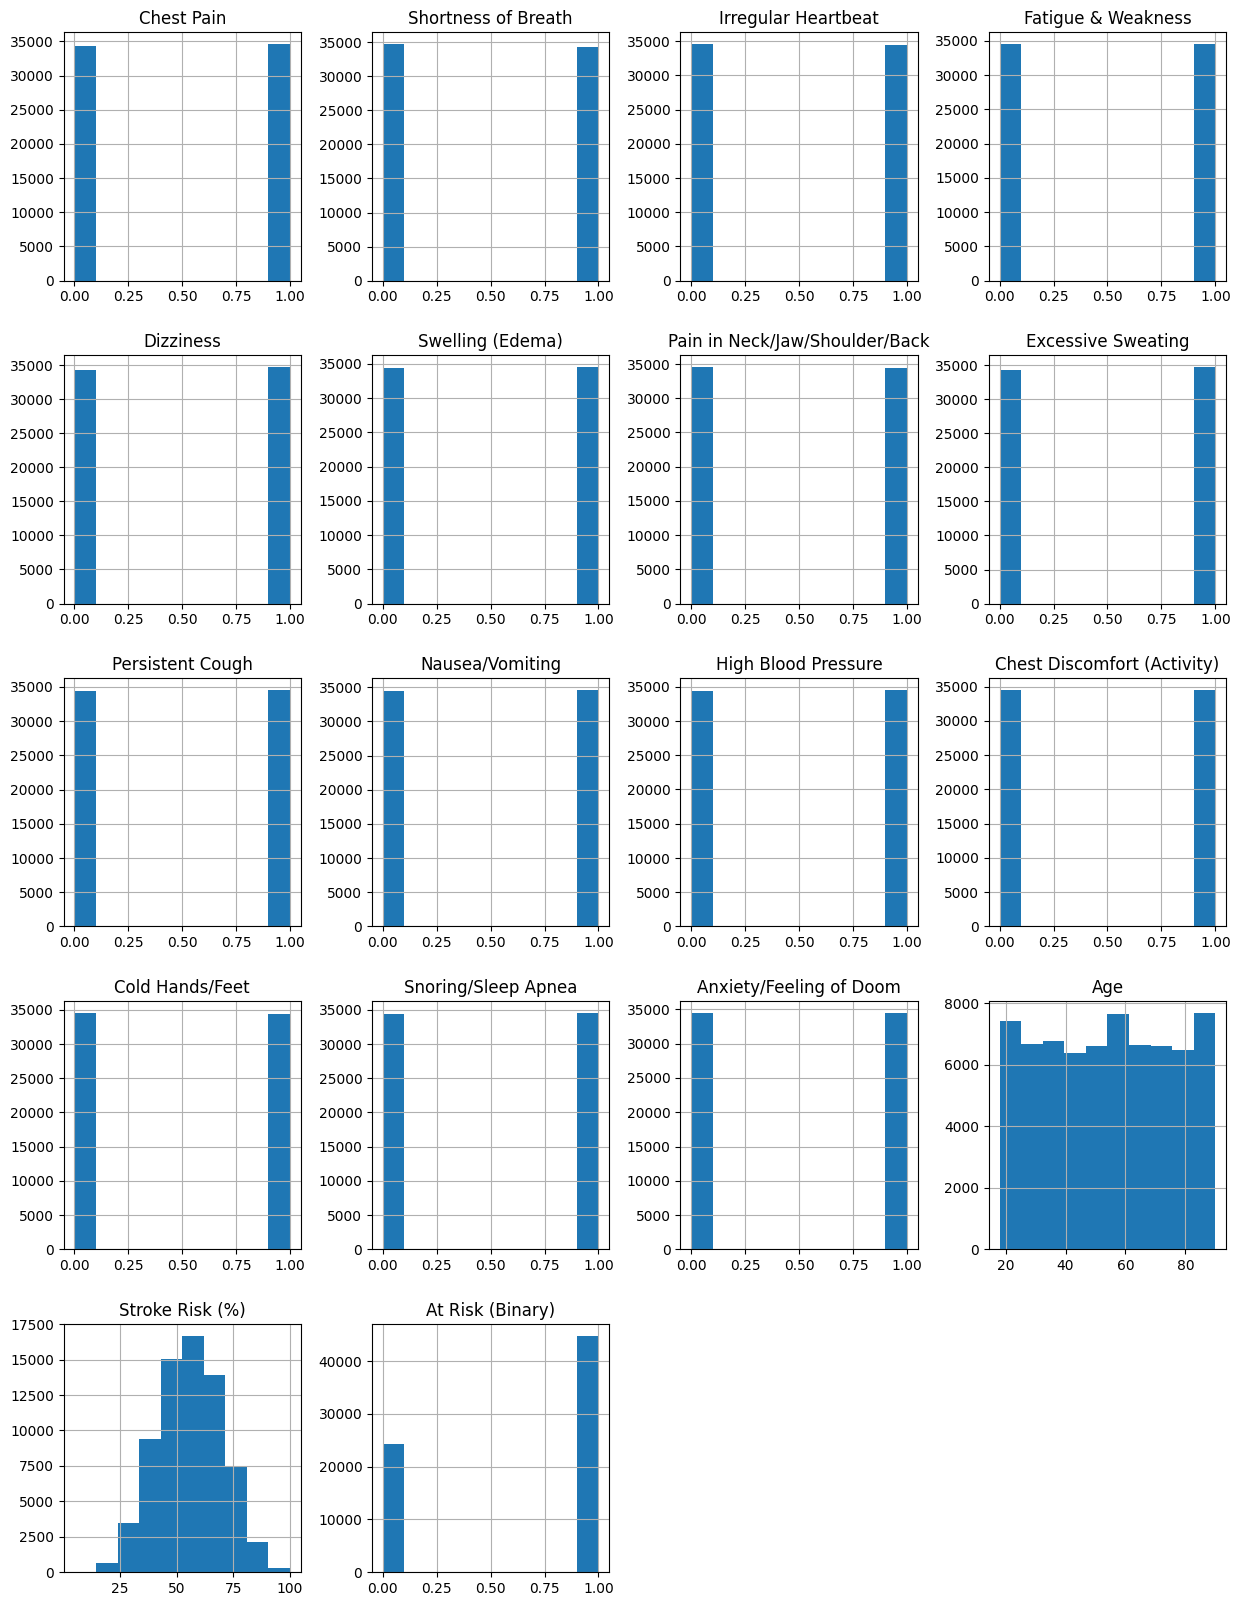

In [30]:
# Plot Histogram to See the Distribution of the Data

fig = plt.figure(figsize = (15,20))
ax = fig.gca()
df.hist(ax = ax)
plt.show()

Only Heart Disease Partipants¶

<ipython-input-31-cf51bdae04a4>:6: UserWarning: To output multiple subplots, the figure containing the passed axes is being cleared.
  dataset_copy.hist(ax = ax)


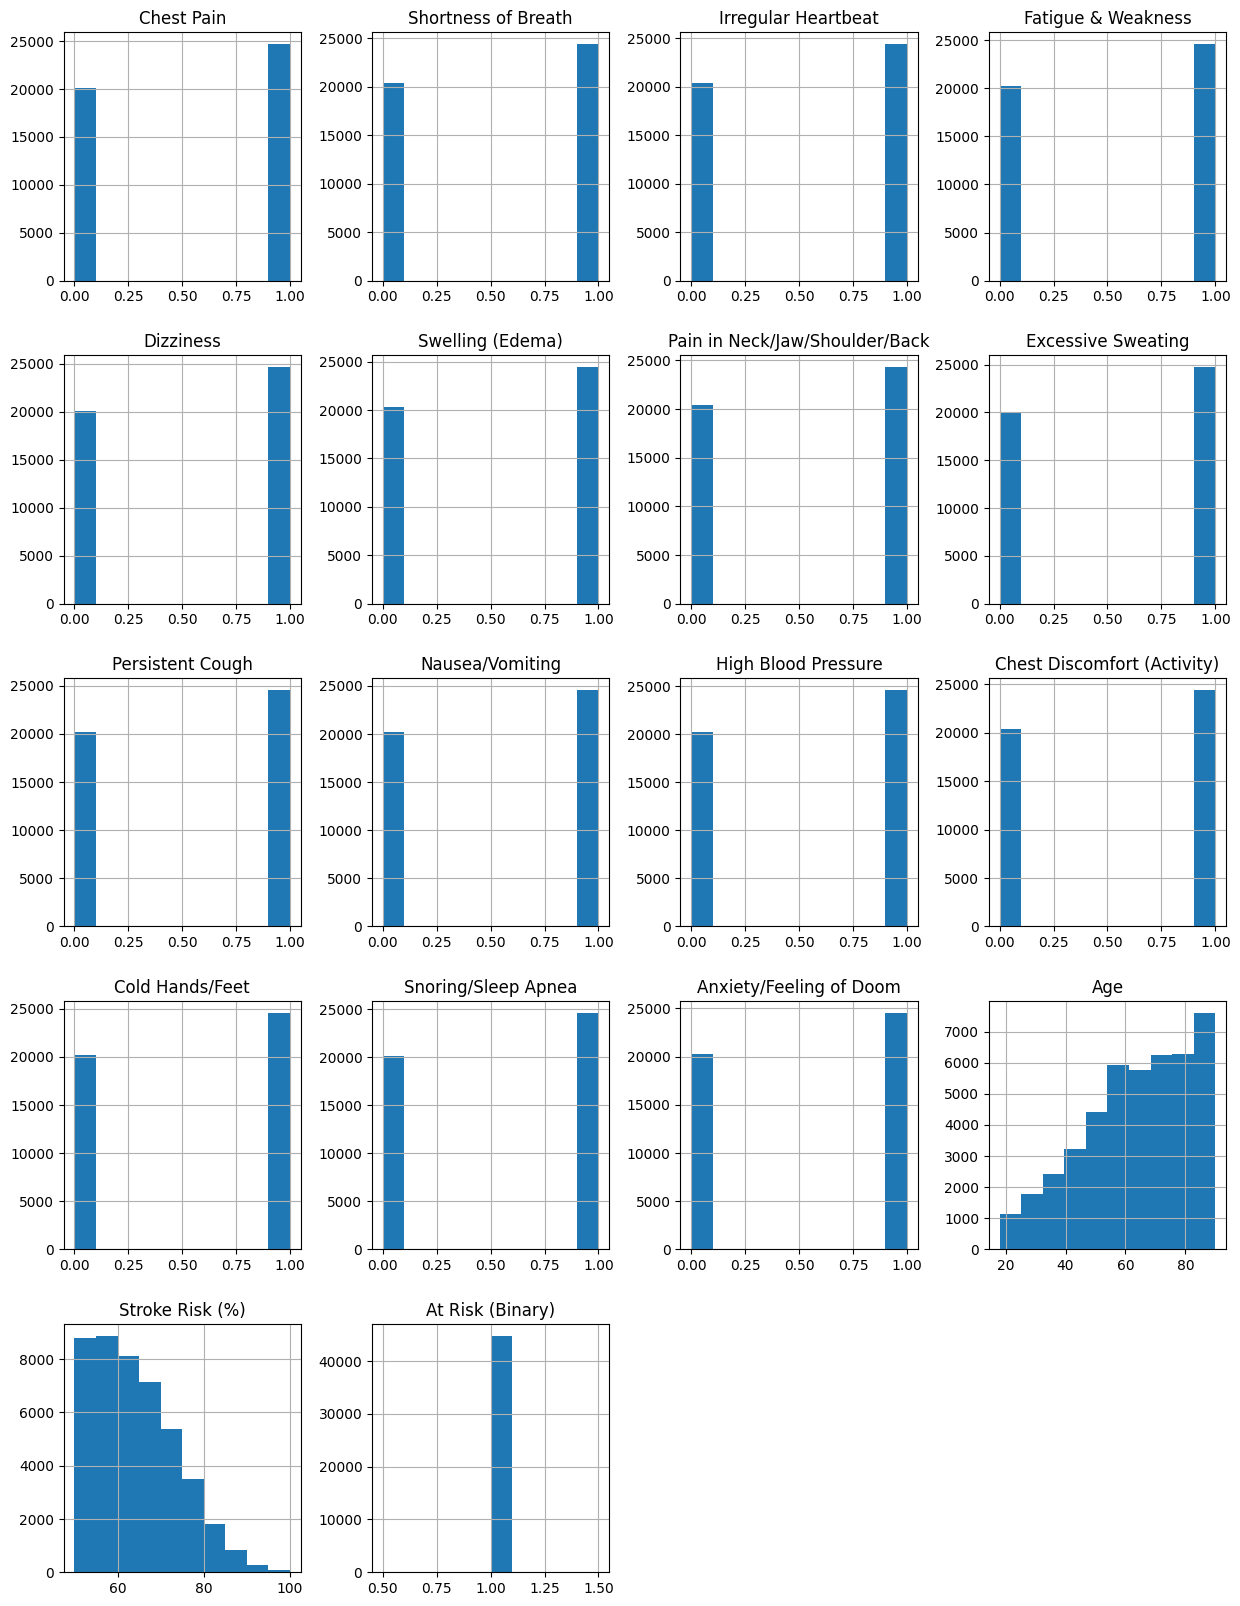

In [31]:
# Plot Histogram to See the Distribution of the Data for Heart Disease Cases
dataset_copy=df[df['At Risk (Binary)']==1]
columns=df.columns[:21]
fig = plt.figure(figsize = (15,20))
ax = fig.gca()
dataset_copy.hist(ax = ax)
plt.show()

In [32]:
def plot_histogram(df, numerical_cols):
    """Plot histograms for numerical features to visualize their distributions."""
    num_plots = len(numerical_cols)
    num_rows = (num_plots // 3) + (1 if num_plots % 3 != 0 else 0)  
    
    fig, axes = plt.subplots(num_rows, 3, figsize=(15, num_rows * 5))
    axes = axes.flatten()
    
    for i, col in enumerate(numerical_cols):
        sns.histplot(df[col], kde=False, bins=30, color='skyblue', edgecolor='black', ax=axes[i])
        axes[i].set_title(f"Histogram of {col}")
        axes[i].set_xlabel(col)
        axes[i].set_ylabel("Frequency")
    
    for i in range(num_plots, len(axes)):
        axes[i].axis('off') 
    
    plt.tight_layout()
    plt.show()

In [33]:
def plot_boxplot(df, numerical_cols):
    """Plot boxplots for numerical features to visualize the distribution and detect outliers."""
    num_plots = len(numerical_cols)
    num_rows = (num_plots // 3) + (1 if num_plots % 3 != 0 else 0)
    
    fig, axes = plt.subplots(num_rows, 3, figsize=(15, num_rows * 5))
    axes = axes.flatten() 
    
    for i, col in enumerate(numerical_cols):
        sns.boxplot(x=df[col], color='lightgreen', ax=axes[i])
        axes[i].set_title(f"Boxplot of {col}")
        axes[i].set_xlabel(col)
    
    for i in range(num_plots, len(axes)):
        axes[i].axis('off') 
    
    plt.tight_layout()
    plt.show()

In [34]:
def plot_kde(df, numerical_cols):
    """Plot KDE (Kernel Density Estimate) for numerical features to visualize smooth distributions."""
    num_plots = len(numerical_cols)
    num_rows = (num_plots // 3) + (1 if num_plots % 3 != 0 else 0)
    
    fig, axes = plt.subplots(num_rows, 3, figsize=(15, num_rows * 5))
    axes = axes.flatten()
    
    for i, col in enumerate(numerical_cols):
        sns.kdeplot(df[col], shade=True, color='blue', alpha=0.5, ax=axes[i])
        axes[i].set_title(f"KDE of {col}")
        axes[i].set_xlabel(col)
        axes[i].set_ylabel("Density")
    
    for i in range(num_plots, len(axes)):
        axes[i].axis('off') 
    
    plt.tight_layout()
    plt.show()

/usr/local/lib/python3.10/dist-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
/usr/local/lib/python3.10/dist-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


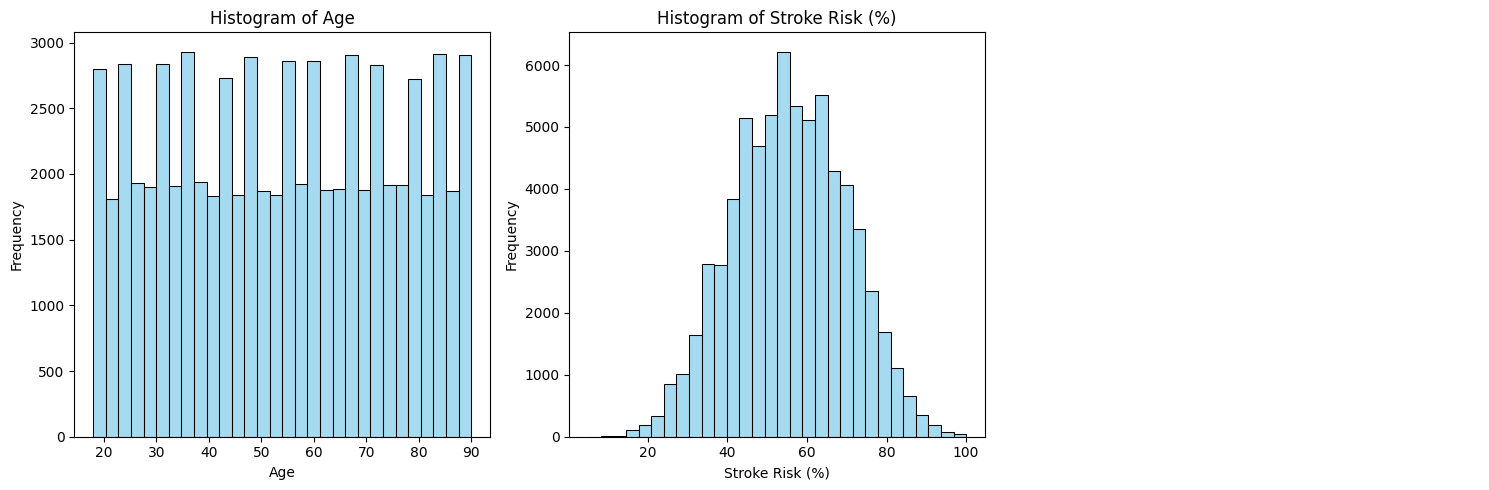

In [35]:
plot_histogram(df, filtered_classification["numerical"])

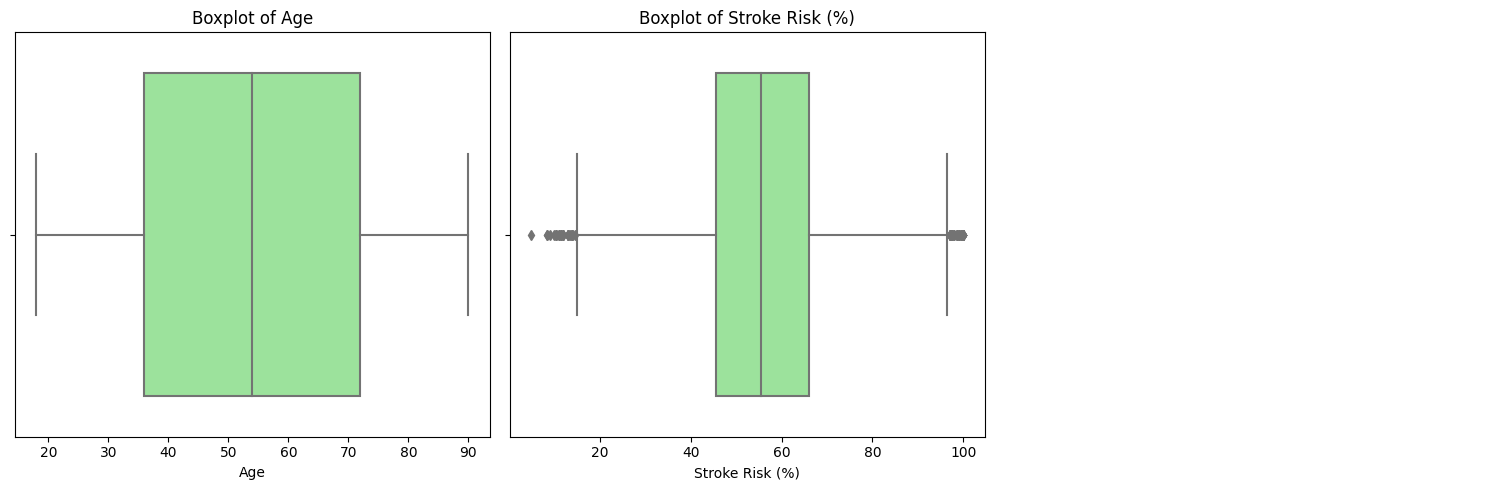

In [36]:
plot_boxplot(df, filtered_classification["numerical"])

<ipython-input-34-d2d2644a338c>:10: FutureWarning: 

`shade` is now deprecated in favor of `fill`; setting `fill=True`.
This will become an error in seaborn v0.14.0; please update your code.

  sns.kdeplot(df[col], shade=True, color='blue', alpha=0.5, ax=axes[i])
/usr/local/lib/python3.10/dist-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
<ipython-input-34-d2d2644a338c>:10: FutureWarning: 

`shade` is now deprecated in favor of `fill`; setting `fill=True`.
This will become an error in seaborn v0.14.0; please update your code.

  sns.kdeplot(df[col], shade=True, color='blue', alpha=0.5, ax=axes[i])
/usr/local/lib/python3.10/dist-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.


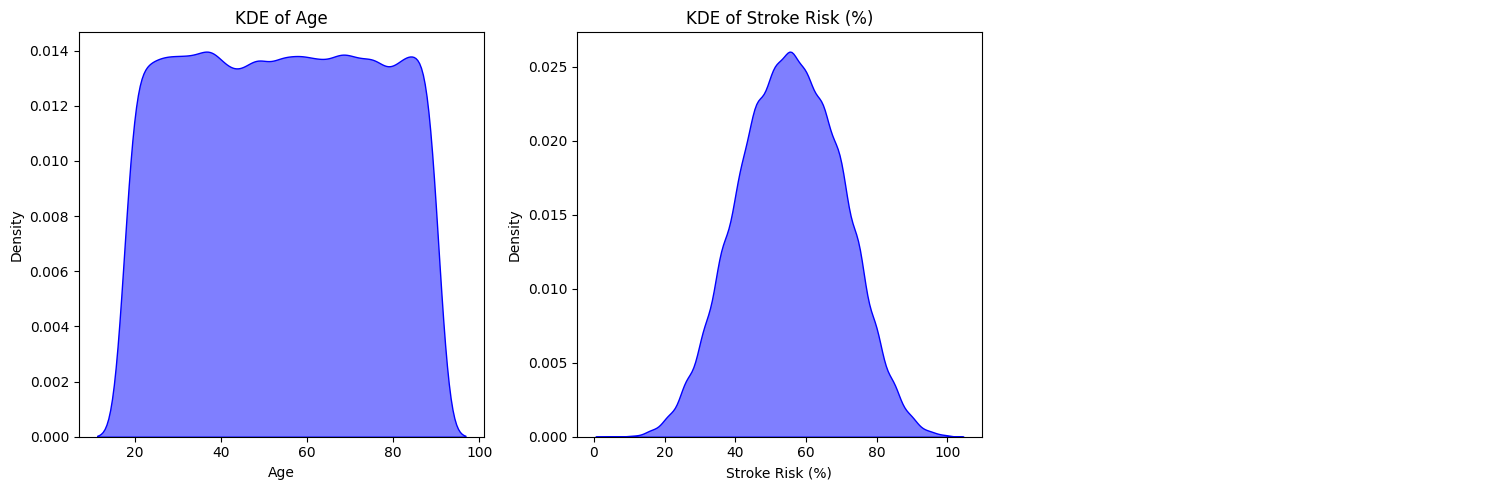

In [37]:
plot_kde(df, filtered_classification["numerical"])

In [38]:
def plot_barplot(df, categorical_cols):
    """Plot bar plots for categorical features to visualize the distribution of different categories."""
    num_plots = len(categorical_cols)
    num_rows = (num_plots // 3) + (1 if num_plots % 3 != 0 else 0) 
    
    fig, axes = plt.subplots(num_rows, 3, figsize=(15, num_rows * 5))
    axes = axes.flatten() 
    
    for i, col in enumerate(categorical_cols):
        sns.countplot(x=df[col], palette="Set2", ax=axes[i])
        axes[i].set_title(f"Bar Plot of {col}")
        axes[i].set_xlabel(col)
        axes[i].set_ylabel("Count")
    
    for i in range(num_plots, len(axes)):
        axes[i].axis('off') 
    
    plt.tight_layout()
    plt.show()

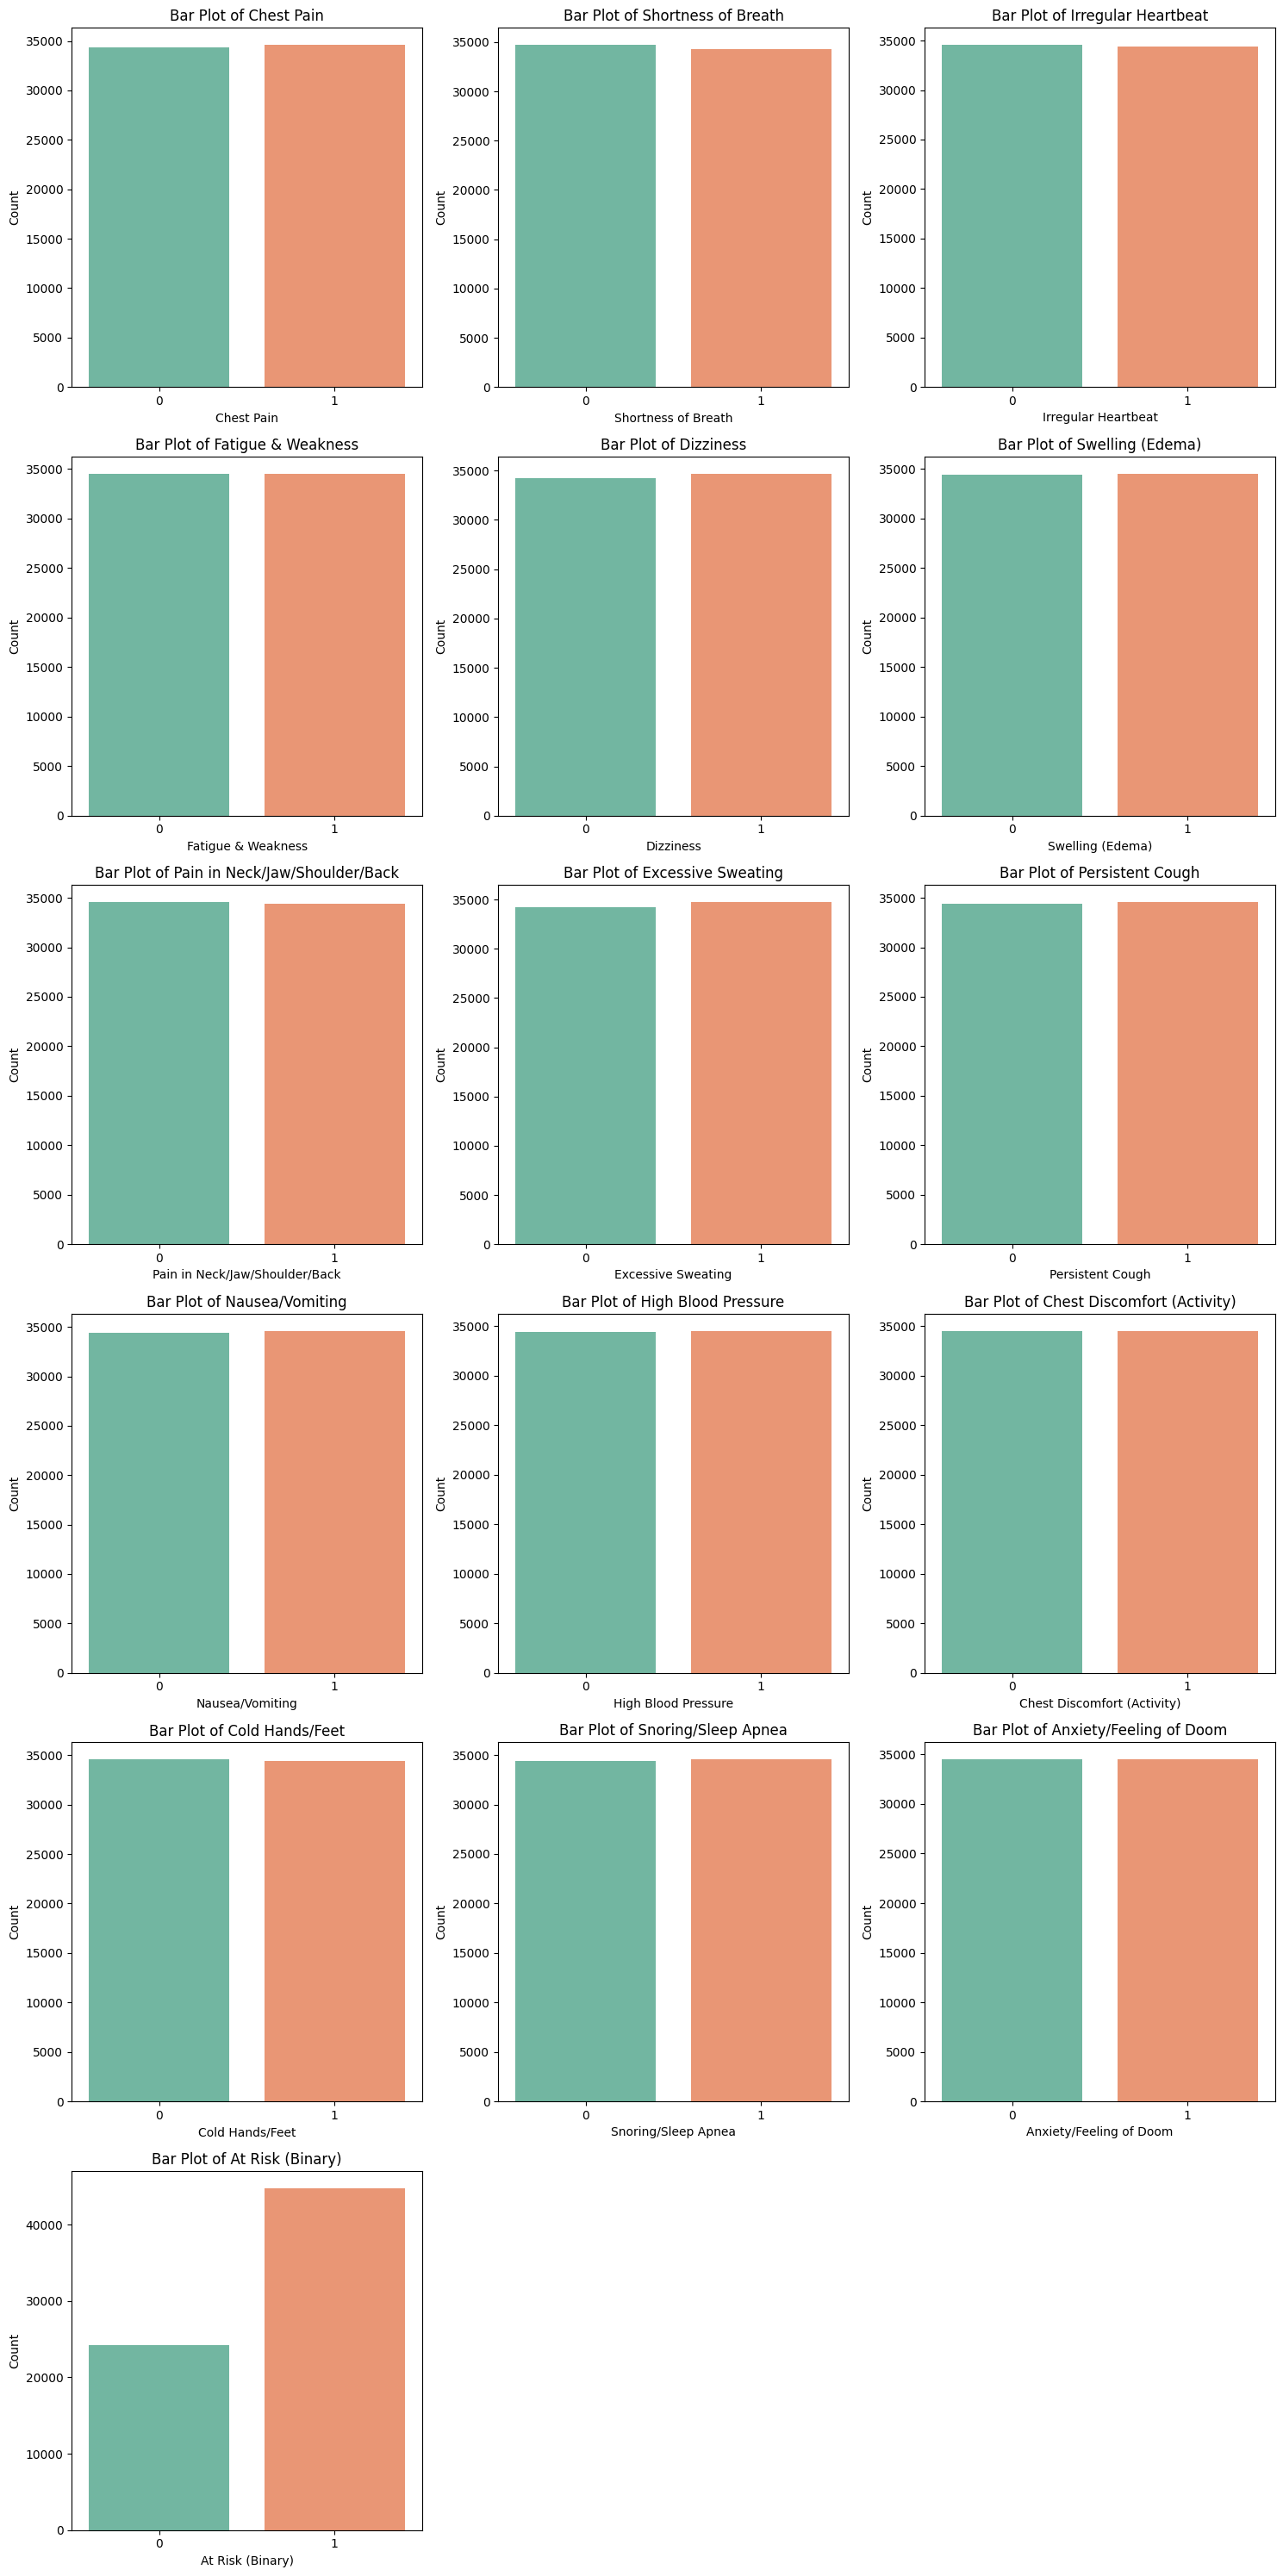

In [39]:
plot_barplot(df, filtered_classification["binary"])

In [40]:
# At Risk (Binary)
# Check for class imbalance
df['At Risk (Binary)'].value_counts()/len(df)

At Risk (Binary)
1    0.649212
0    0.350788
Name: count, dtype: float64

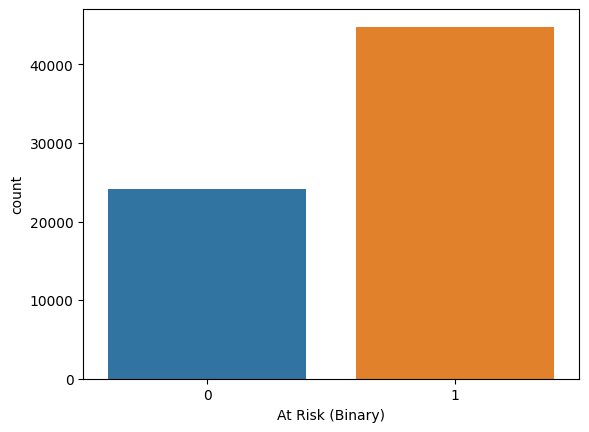

In [41]:
sns.countplot(x='At Risk (Binary)',data=df)
plt.show()

<div style="border: 10px solid black; background-color:#ffd700; color:black; text-align:left; padding: 30px; font-size:40px; font-family:Verdana, sans-serif;">
<b>5. Outlier Detection</b>
</div>

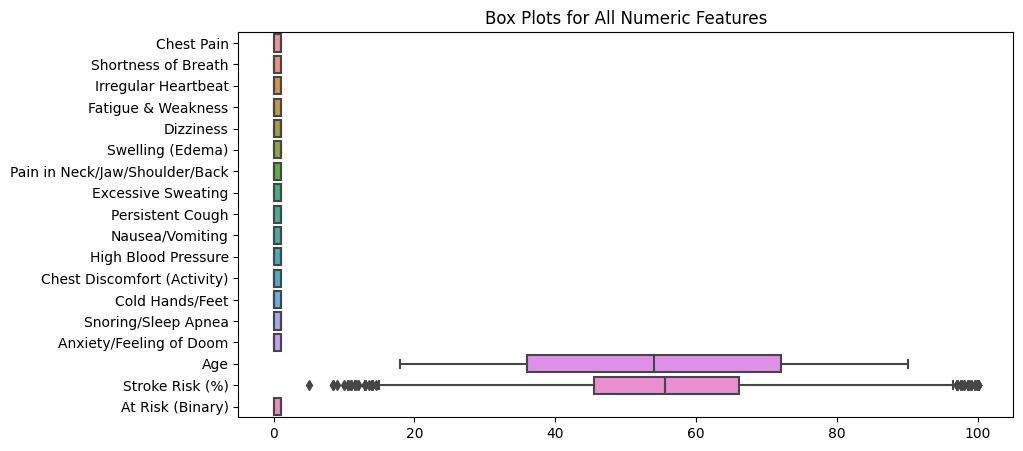

In [42]:
#Check for outliers
import seaborn as sns
import matplotlib.pyplot as plt

# Select only numeric columns (exclude categorical)
numeric_cols = df.select_dtypes(include=['int64', 'float64']).columns

# Plot boxplots for all numeric features
plt.figure(figsize=(10, 5))  # Adjust figure size
sns.boxplot(data=df[numeric_cols], orient="h")  # Horizontal boxplots
plt.title("Box Plots for All Numeric Features")
plt.show()

In [43]:
def plot_boxplots(df, numerical_cols):
    """Plot box plots for numerical features to visualize outliers."""
    num_plots = len(numerical_cols)
    num_rows = (num_plots // 3) + (1 if num_plots % 3 != 0 else 0)
    
    fig, axes = plt.subplots(num_rows, 3, figsize=(15, num_rows * 5))
    axes = axes.flatten()
    
    for i, col in enumerate(numerical_cols):
        sns.boxplot(x=df[col], ax=axes[i], color='lightcoral')
        axes[i].set_title(f"Boxplot of {col}")

    for j in range(i + 1, len(axes)):
        fig.delaxes(axes[j])

    plt.tight_layout()
    plt.show()

In [44]:
def plot_violinplots(df, numerical_cols):
    """Plot violin plots for numerical features to visualize distribution and outliers."""
    num_plots = len(numerical_cols)
    cols_per_row = 3 
    rows = (num_plots // cols_per_row) + (num_plots % cols_per_row > 0)  

    fig, axes = plt.subplots(rows, cols_per_row, figsize=(15, 5 * rows))
    axes = axes.flatten() 

    for i, col in enumerate(numerical_cols):
        sns.violinplot(x=df[col], ax=axes[i], color='teal')
        axes[i].set_title(f"Violin Plot of {col}")

    for j in range(i + 1, len(axes)):
        fig.delaxes(axes[j])

    plt.tight_layout()
    plt.show()

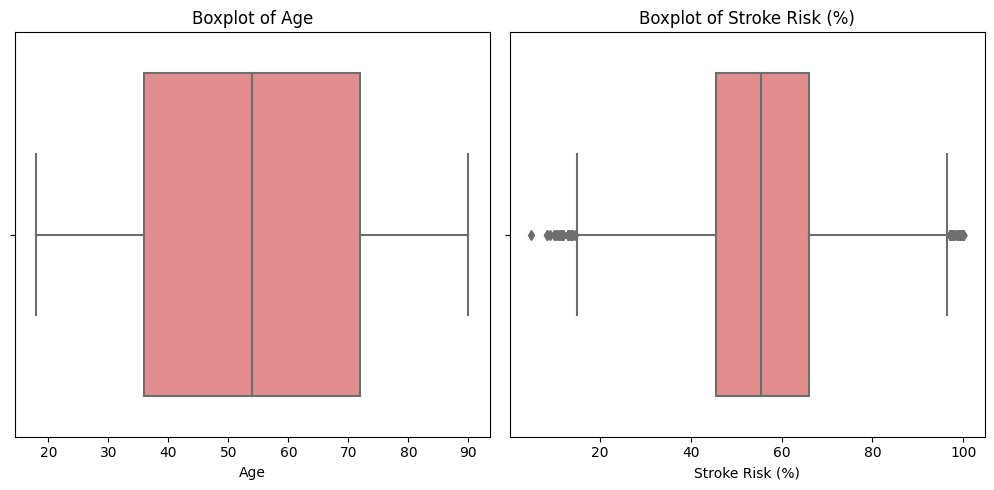

In [45]:
plot_boxplots(df, filtered_classification["numerical"])

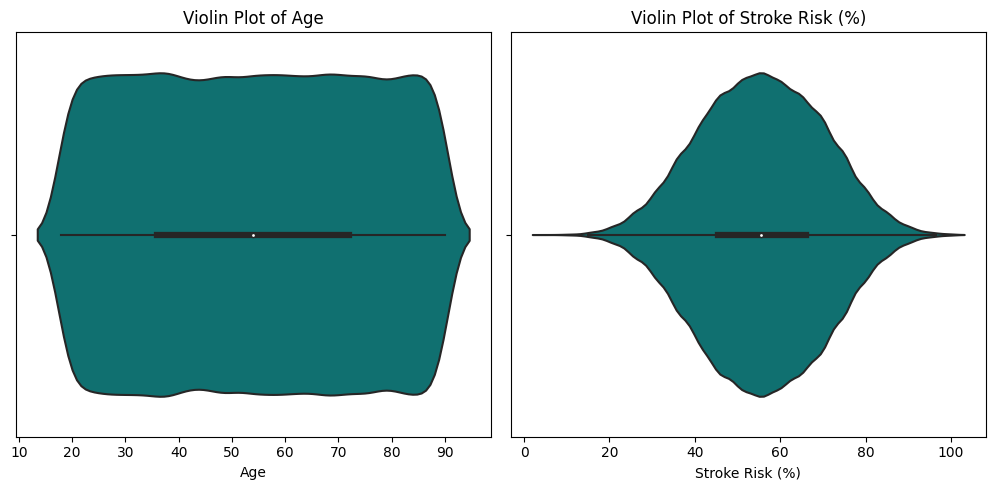

In [46]:
plot_violinplots(df, filtered_classification["numerical"])

In [47]:
def remove_outliers(df, numerical_cols, method="IQR"):
    """Remove rows containing outliers from numerical columns using IQR or Z-score."""
    df_clean = df.copy()
    
    for col in numerical_cols:
        if method == "IQR":
            Q1 = df[col].quantile(0.25)
            Q3 = df[col].quantile(0.75)
            IQR = Q3 - Q1
            lower_bound = Q1 - 1.5 * IQR
            upper_bound = Q3 + 1.5 * IQR
            df_clean = df_clean[(df_clean[col] >= lower_bound) & (df_clean[col] <= upper_bound)]
        elif method == "Z-score":
            mean = df[col].mean()
            std_dev = df[col].std()
            df_clean = df_clean[(np.abs((df[col] - mean) / std_dev) < 3)]
    
        print(f"🔹 Outliers removed in column '{col}' using {method} method.")
    
    return df_clean

In [48]:
def transform_outliers(df, numerical_cols, method="winsorize"):
    """Transform outliers in numerical columns using winsorization, log, or square root transformation."""
    df_transformed = df.copy()
    
    for col in numerical_cols:
        if method == "winsorize":
            df_transformed[col] = winsorize(df[col], limits=[0.05, 0.05])
        elif method == "log":
            df_transformed[col] = np.log1p(df[col])       
        elif method == "sqrt":
            df_transformed[col] = np.sqrt(df[col])
        
        print(f"🔹 Outliers in '{col}' transformed using {method} method.")
    
    return df_transformed

In [49]:
transform_required_columns = ["Stroke Risk (%)"]
df = transform_outliers(df, transform_required_columns)

🔹 Outliers in 'Stroke Risk (%)' transformed using winsorize method.


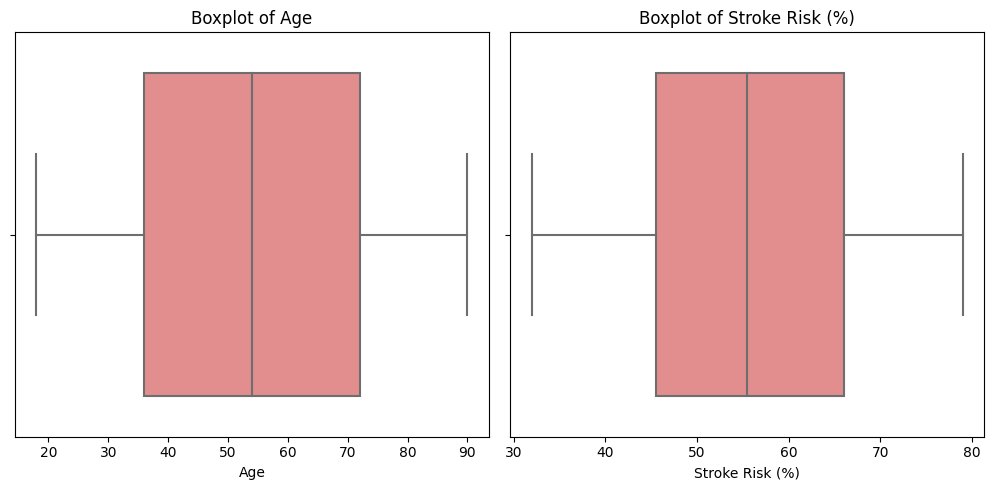

In [50]:
plot_boxplots(df, filtered_classification["numerical"])

<div style="border: 10px solid black; background-color:#ffd700; color:black; text-align:left; padding: 30px; font-size:40px; font-family:Verdana, sans-serif;">
<b>6. Correlation Analysis</b>
</div>

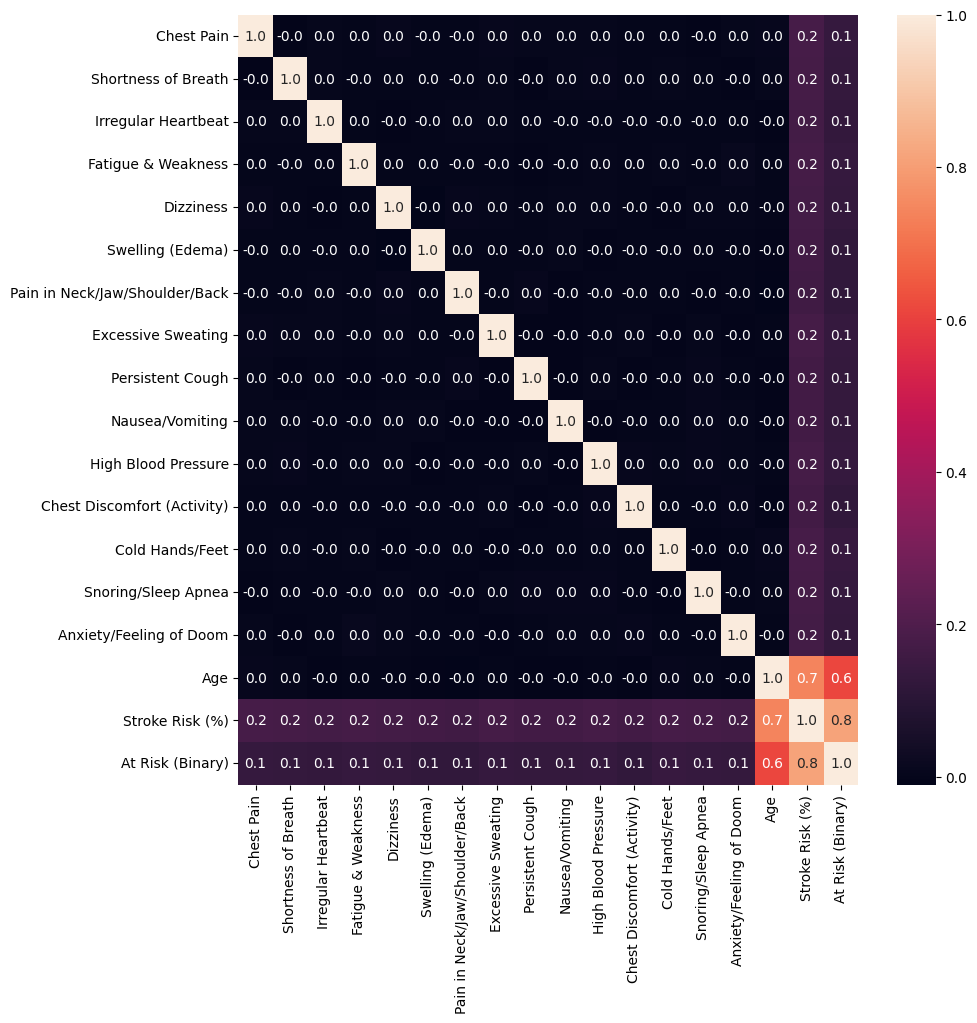

In [51]:
plt.figure(figsize=(10,10))
sns.heatmap(df.corr(),annot=True,fmt='.1f')
plt.show()

In [52]:
def plot_correlation_heatmap(df, numerical_cols):
    """Plot a heatmap to visualize the correlation between numerical features."""
    plt.figure(figsize=(12, 6))
    correlation_matrix = df[numerical_cols].corr() 
    sns.heatmap(correlation_matrix, annot=True, cmap="coolwarm", fmt=".2f", linewidths=0.5)
    plt.title("🔹 Correlation Heatmap")
    plt.show()

In [53]:
def plot_pairplot(df, numerical_cols):
    """Plot pairplot for numerical columns to observe feature relationships."""
    sns.pairplot(df[numerical_cols], diag_kind="kde", corner=True)  
    plt.show()

/usr/local/lib/python3.10/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 128313 (\N{SMALL BLUE DIAMOND}) missing from current font.
  fig.canvas.print_figure(bytes_io, **kw)


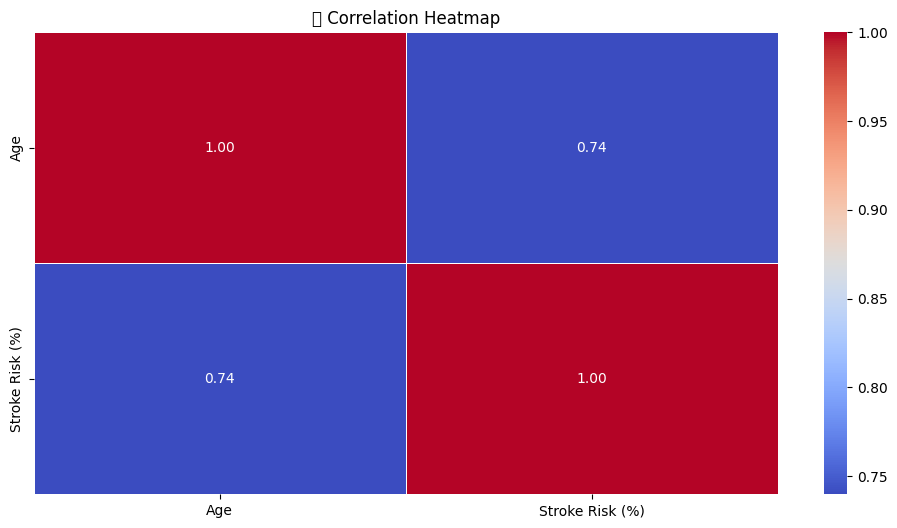

In [54]:
plot_correlation_heatmap(df, filtered_classification["numerical"])

/usr/local/lib/python3.10/dist-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
/usr/local/lib/python3.10/dist-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


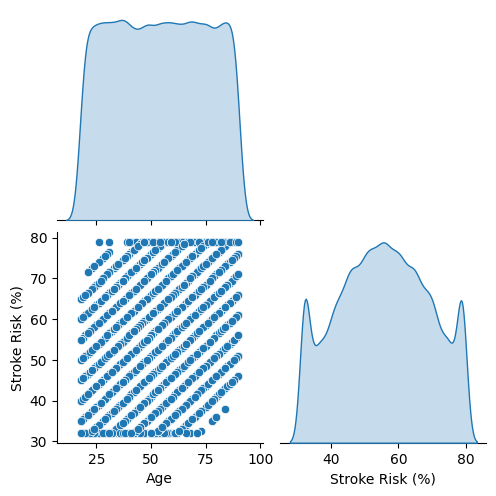

In [55]:
plot_pairplot(df, filtered_classification["numerical"])

<div style="border: 10px solid black; background-color:#ffd700; color:black; text-align:left; padding: 30px; font-size:40px; font-family:Verdana, sans-serif;">
<b>7. Train-Test Split & Sampling Strategy</b>
</div>

In [56]:
def train_test_split_custom(df, target_col, test_size=0.2, stratify=True, random_state=42):
    """Function to split data into training and testing sets."""
    X = df.drop(columns=[target_col]) 
    y = df[target_col] 

    if stratify:
        X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=test_size, stratify=y, random_state=random_state)
    else:
        X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=test_size, random_state=random_state)
    
    return X_train, X_test, y_train, y_test

In [57]:
X_train, X_test, y_train, y_test = train_test_split_custom(df, "At Risk (Binary)", test_size=0.1)

In [58]:
X_train

,Chest Pain,Shortness of Breath,Irregular Heartbeat,Fatigue & Weakness,Dizziness,Swelling (Edema),Pain in Neck/Jaw/Shoulder/Back,Excessive Sweating,Persistent Cough,Nausea/Vomiting,High Blood Pressure,Chest Discomfort (Activity),Cold Hands/Feet,Snoring/Sleep Apnea,Anxiety/Feeling of Doom,Age,Stroke Risk (%)
50679,0,0,0,1,1,0,0,1,1,1,0,0,0,0,1,42,42.0
11649,0,1,1,0,0,0,1,1,0,0,1,1,0,1,1,65,63.5
11161,0,0,1,1,1,0,1,1,1,1,1,1,0,0,1,82,79.0
50822,1,1,1,0,0,0,1,0,0,0,0,1,0,0,0,69,50.5
5863,0,1,0,0,1,0,0,0,1,1,1,1,0,0,1,40,46.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
48954,1,1,1,1,0,0,0,1,1,1,1,1,0,1,0,42,62.0
49297,1,1,1,0,0,1,1,0,0,0,1,1,1,1,0,79,75.5
7463,1,0,1,1,0,1,1,0,1,1,1,1,0,0,1,37,59.5
46738,0,0,0,1,0,1,1,0,1,0,1,1,1,0,0,35,43.5


In [59]:
X_test

,Chest Pain,Shortness of Breath,Irregular Heartbeat,Fatigue & Weakness,Dizziness,Swelling (Edema),Pain in Neck/Jaw/Shoulder/Back,Excessive Sweating,Persistent Cough,Nausea/Vomiting,High Blood Pressure,Chest Discomfort (Activity),Cold Hands/Feet,Snoring/Sleep Apnea,Anxiety/Feeling of Doom,Age,Stroke Risk (%)
67791,0,1,0,1,0,1,1,0,1,1,1,1,0,0,0,38,50.0
54574,1,0,0,1,0,0,0,1,1,1,1,1,0,0,0,51,51.5
3678,1,0,0,1,1,1,1,1,0,1,1,0,1,0,1,19,50.5
5331,1,1,0,1,1,0,0,1,0,1,0,1,1,1,1,46,64.0
6423,1,1,1,1,1,1,1,1,0,1,1,1,1,1,0,85,79.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
64988,1,1,1,0,0,0,1,0,0,0,1,1,0,1,1,21,41.5
21404,1,0,1,0,0,0,1,1,0,1,0,0,1,0,0,84,63.0
28813,1,0,1,0,0,1,1,0,1,1,1,0,1,1,0,38,55.0
9510,1,0,0,0,1,0,0,1,0,0,1,1,1,0,0,74,58.0


In [60]:
y_train

50679    0
11649    1
11161    1
50822    1
5863     0
        ..
48954    1
49297    1
7463     1
46738    0
20179    1
Name: At Risk (Binary), Length: 62081, dtype: int64

In [61]:
y_test

67791    1
54574    1
3678     1
5331     1
6423     1
        ..
64988    0
21404    1
28813    1
9510     1
12030    1
Name: At Risk (Binary), Length: 6898, dtype: int64

<div style="border: 10px solid black; background-color:#ffd700; color:black; text-align:left; padding: 30px; font-size:40px; font-family:Verdana, sans-serif;">
<b>8. Model Selection & Training</b>
</div>

In [62]:
warnings.filterwarnings("ignore")

In [63]:
def scale_data(X):
    """Scale the data using StandardScaler."""
    scaler = StandardScaler()
    X_scaled = scaler.fit_transform(X)
    return X_scaled

In [64]:
X_train = scale_data(X_train)
X_test = scale_data(X_test)

In [65]:
X_train

array([[-1.00372789, -0.99177046, -0.99895353, ...,  1.00098307,
        -0.57274557, -1.01874855],
       [-1.00372789,  1.00829782,  1.00104757, ...,  1.00098307,
         0.51782896,  0.59587626],
       [-1.00372789, -0.99177046,  1.00104757, ...,  1.00098307,
         1.32390578,  1.7599081 ],
       ...,
       [ 0.99628595, -0.99177046,  1.00104757, ...,  1.00098307,
        -0.80982699,  0.29548094],
       [-1.00372789, -0.99177046, -0.99895353, ..., -0.99901789,
        -0.90465955, -0.90610031],
       [-1.00372789, -0.99177046,  1.00104757, ..., -0.99901789,
         0.18591497, -0.04246378]])

In [66]:
X_test

array([[-0.99797248,  0.99133933, -0.99105192, ..., -1.00698292,
        -0.7570678 , -0.41825139],
       [ 1.00203164, -1.00873633, -0.99105192, ..., -1.00698292,
        -0.13489234, -0.30566073],
       [ 1.00203164, -1.00873633, -0.99105192, ...,  0.9930655 ,
        -1.66640118, -0.38072117],
       ...,
       [ 1.00203164, -1.00873633,  1.00902887, ..., -1.00698292,
        -0.7570678 , -0.0429492 ],
       [ 1.00203164, -1.00873633, -0.99105192, ..., -1.00698292,
         0.96587964,  0.18223212],
       [ 1.00203164, -1.00873633, -0.99105192, ...,  0.9930655 ,
         0.63086208,  1.04542717]])

In [67]:
def train_models(X_train, X_test, y_train, y_test):
    """Train and compare multiple classification models"""
    models = {
        "Logistic Regression": LogisticRegression(),
        "Random Forest": RandomForestClassifier(),
        "Gradient Boosting": GradientBoostingClassifier(),
        "SVM": SVC(),
        "XGBoost": XGBClassifier()
    }

    results = {}
    
    print("🔹🔹🔹🔹🔹🔹🔹🔹🔹🔹🔹🔹🔹🔹🔹🔹🔹🔹🔹🔹🔹🔹")
    for name, model in models.items():
        model.fit(X_train, y_train)
        y_pred = model.predict(X_test)
        acc = accuracy_score(y_test, y_pred)
        results[name] = acc
        print("🔹🔹🔹🔹🔹🔹🔹🔹🔹🔹🔹🔹🔹🔹🔹🔹🔹🔹🔹🔹🔹🔹")
        print(f"{name}\nAccuracy: {acc:.4f}")
        print(f"Confusion Matrix:\n{confusion_matrix(y_test, y_pred)}\n")
        print("🔹🔹🔹🔹🔹🔹🔹🔹🔹🔹🔹🔹🔹🔹🔹🔹🔹🔹🔹🔹🔹🔹")
    
    print("🔹🔹🔹🔹🔹🔹🔹🔹🔹🔹🔹🔹🔹🔹🔹🔹🔹🔹🔹🔹🔹🔹")
    
    return results

In [68]:
results = train_models(X_train, X_test, y_train, y_test)

🔹🔹🔹🔹🔹🔹🔹🔹🔹🔹🔹🔹🔹🔹🔹🔹🔹🔹🔹🔹🔹🔹
🔹🔹🔹🔹🔹🔹🔹🔹🔹🔹🔹🔹🔹🔹🔹🔹🔹🔹🔹🔹🔹🔹
Logistic Regression
Accuracy: 1.0000
Confusion Matrix:
[[2420    0]
 [   0 4478]]

🔹🔹🔹🔹🔹🔹🔹🔹🔹🔹🔹🔹🔹🔹🔹🔹🔹🔹🔹🔹🔹🔹
🔹🔹🔹🔹🔹🔹🔹🔹🔹🔹🔹🔹🔹🔹🔹🔹🔹🔹🔹🔹🔹🔹
Random Forest
Accuracy: 1.0000
Confusion Matrix:
[[2420    0]
 [   0 4478]]

🔹🔹🔹🔹🔹🔹🔹🔹🔹🔹🔹🔹🔹🔹🔹🔹🔹🔹🔹🔹🔹🔹
🔹🔹🔹🔹🔹🔹🔹🔹🔹🔹🔹🔹🔹🔹🔹🔹🔹🔹🔹🔹🔹🔹
Gradient Boosting
Accuracy: 1.0000
Confusion Matrix:
[[2420    0]
 [   0 4478]]

🔹🔹🔹🔹🔹🔹🔹🔹🔹🔹🔹🔹🔹🔹🔹🔹🔹🔹🔹🔹🔹🔹
🔹🔹🔹🔹🔹🔹🔹🔹🔹🔹🔹🔹🔹🔹🔹🔹🔹🔹🔹🔹🔹🔹
SVM
Accuracy: 0.9936
Confusion Matrix:
[[2395   25]
 [  19 4459]]

🔹🔹🔹🔹🔹🔹🔹🔹🔹🔹🔹🔹🔹🔹🔹🔹🔹🔹🔹🔹🔹🔹
🔹🔹🔹🔹🔹🔹🔹🔹🔹🔹🔹🔹🔹🔹🔹🔹🔹🔹🔹🔹🔹🔹
XGBoost
Accuracy: 0.9858
Confusion Matrix:
[[2420    0]
 [  98 4380]]

🔹🔹🔹🔹🔹🔹🔹🔹🔹🔹🔹🔹🔹🔹🔹🔹🔹🔹🔹🔹🔹🔹
🔹🔹🔹🔹🔹🔹🔹🔹🔹🔹🔹🔹🔹🔹🔹🔹🔹🔹🔹🔹🔹🔹


In [69]:
import pandas as pd
from sklearn.metrics import (classification_report, accuracy_score, precision_score, 
                             recall_score, f1_score, confusion_matrix, mean_squared_error, 
                             mean_absolute_error, roc_auc_score)
import numpy as np
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.svm import SVC
import xgboost as xgb
from sklearn.neural_network import MLPClassifier
from sklearn.naive_bayes import GaussianNB

# List to store performance metrics for each model
performance_metrics = []

# Function to multiply by 100 and round to 2 decimal places
def process_metric(value):
    return round(value * 100, 2)

# Logistic Regression
logreg = LogisticRegression()
logreg.fit(X_train, y_train)
y_pred_logreg = logreg.predict(X_test)
acc_logreg = process_metric(accuracy_score(y_test, y_pred_logreg))
precision_logreg = process_metric(precision_score(y_test, y_pred_logreg))
recall_logreg = process_metric(recall_score(y_test, y_pred_logreg))
f1_logreg = process_metric(f1_score(y_test, y_pred_logreg))
tn_logreg, fp_logreg, fn_logreg, tp_logreg = confusion_matrix(y_test, y_pred_logreg).ravel()
specificity_logreg = process_metric(tn_logreg / (tn_logreg + fp_logreg))
tpr_logreg = process_metric(tp_logreg / (tp_logreg + fn_logreg))
fpr_logreg = process_metric(fp_logreg / (fp_logreg + tn_logreg))
csi_logreg = process_metric(tp_logreg / (tp_logreg + fp_logreg + fn_logreg))
mse_logreg = mean_squared_error(y_test, y_pred_logreg)
rmse_logreg = process_metric(np.sqrt(mse_logreg))
mae_logreg = mean_absolute_error(y_test, y_pred_logreg)

performance_metrics.append({
    'Model': 'Logistic Regression',
    'Accuracy': acc_logreg,
    'Precision': precision_logreg,
    'Sensitivity (Recall)': recall_logreg,
    'F1 Score': f1_logreg,
    'Specificity': specificity_logreg,
    'TPR': tpr_logreg,
    'FPR': fpr_logreg,
    'CSI': csi_logreg,
    'MAE': mae_logreg,
    'MSE': mse_logreg,
    'RMSE': rmse_logreg
})

# Random Forest
rf = RandomForestClassifier(n_estimators=100, random_state=42)
rf.fit(X_train, y_train)
y_pred_rf = rf.predict(X_test)
acc_rf = process_metric(accuracy_score(y_test, y_pred_rf))
precision_rf = process_metric(precision_score(y_test, y_pred_rf))
recall_rf = process_metric(recall_score(y_test, y_pred_rf))
f1_rf = process_metric(f1_score(y_test, y_pred_rf))
tn_rf, fp_rf, fn_rf, tp_rf = confusion_matrix(y_test, y_pred_rf).ravel()
specificity_rf = process_metric(tn_rf / (tn_rf + fp_rf))
tpr_rf = process_metric(tp_rf / (tp_rf + fn_rf))
fpr_rf = process_metric(fp_rf / (fp_rf + tn_rf))
csi_rf = process_metric(tp_rf / (tp_rf + fp_rf + fn_rf))
mse_rf = mean_squared_error(y_test, y_pred_rf)
rmse_rf = process_metric(np.sqrt(mse_rf))
mae_rf = mean_absolute_error(y_test, y_pred_rf)

performance_metrics.append({
    'Model': 'Random Forest',
    'Accuracy': acc_rf,
    'Precision': precision_rf,
    'Sensitivity (Recall)': recall_rf,
    'F1 Score': f1_rf,
    'Specificity': specificity_rf,
    'TPR': tpr_rf,
    'FPR': fpr_rf,
    'CSI': csi_rf,
    'MAE': mae_rf,
    'MSE': mse_rf,
    'RMSE': rmse_rf
})

# Support Vector Machine
svm = SVC(kernel='linear', random_state=42)
svm.fit(X_train, y_train)
y_pred_svm = svm.predict(X_test)
acc_svm = process_metric(accuracy_score(y_test, y_pred_svm))
precision_svm = process_metric(precision_score(y_test, y_pred_svm))
recall_svm = process_metric(recall_score(y_test, y_pred_svm))
f1_svm = process_metric(f1_score(y_test, y_pred_svm))
tn_svm, fp_svm, fn_svm, tp_svm = confusion_matrix(y_test, y_pred_svm).ravel()
specificity_svm = process_metric(tn_svm / (tn_svm + fp_svm))
tpr_svm = process_metric(tp_svm / (tp_svm + fn_svm))
fpr_svm = process_metric(fp_svm / (fp_svm + tn_svm))
csi_svm = process_metric(tp_svm / (tp_svm + fp_svm + fn_svm))
mse_svm = mean_squared_error(y_test, y_pred_svm)
rmse_svm = process_metric(np.sqrt(mse_svm))
mae_svm = mean_absolute_error(y_test, y_pred_svm)

performance_metrics.append({
    'Model': 'SVM',
    'Accuracy': acc_svm,
    'Precision': precision_svm,
    'Sensitivity (Recall)': recall_svm,
    'F1 Score': f1_svm,
    'Specificity': specificity_svm,
    'TPR': tpr_svm,
    'FPR': fpr_svm,
    'CSI': csi_svm,
    'MAE': mae_svm,
    'MSE': mse_svm,
    'RMSE': rmse_svm
})

# Gradient Boosting
gbm = GradientBoostingClassifier(n_estimators=100, random_state=42)
gbm.fit(X_train, y_train)
y_pred_gbm = gbm.predict(X_test)
acc_gbm = process_metric(accuracy_score(y_test, y_pred_gbm))
precision_gbm = process_metric(precision_score(y_test, y_pred_gbm))
recall_gbm = process_metric(recall_score(y_test, y_pred_gbm))
f1_gbm = process_metric(f1_score(y_test, y_pred_gbm))
tn_gbm, fp_gbm, fn_gbm, tp_gbm = confusion_matrix(y_test, y_pred_gbm).ravel()
specificity_gbm = process_metric(tn_gbm / (tn_gbm + fp_gbm))
tpr_gbm = process_metric(tp_gbm / (tp_gbm + fn_gbm))
fpr_gbm = process_metric(fp_gbm / (fp_gbm + tn_gbm))
csi_gbm = process_metric(tp_gbm / (tp_gbm + fp_gbm + fn_gbm))
mae_gbm = mean_absolute_error(y_test, y_pred_gbm)
mse_gbm = mean_squared_error(y_test, y_pred_gbm)
rmse_gbm = process_metric(np.sqrt(mse_gbm))

performance_metrics.append({
    'Model': 'Gradient Boosting',
    'Accuracy': acc_gbm,
    'Precision': precision_gbm,
    'Sensitivity (Recall)': recall_gbm,
    'F1 Score': f1_gbm,
    'Specificity': specificity_gbm,
    'TPR': tpr_gbm,
    'FPR': fpr_gbm,
    'CSI': csi_gbm,
    'MAE': mae_gbm,
    'MSE': mse_gbm,
    'RMSE': rmse_gbm
})

# XGBoost
xgb_model = xgb.XGBClassifier(use_label_encoder=False, eval_metric='mlogloss')
xgb_model.fit(X_train, y_train)
y_pred_xgb = xgb_model.predict(X_test)
acc_xgb = process_metric(accuracy_score(y_test, y_pred_xgb))
precision_xgb = process_metric(precision_score(y_test, y_pred_xgb))
recall_xgb = process_metric(recall_score(y_test, y_pred_xgb))
f1_xgb = process_metric(f1_score(y_test, y_pred_xgb))
tn_xgb, fp_xgb, fn_xgb, tp_xgb = confusion_matrix(y_test, y_pred_xgb).ravel()
specificity_xgb = process_metric(tn_xgb / (tn_xgb + fp_xgb))
tpr_xgb = process_metric(tp_xgb / (tp_xgb + fn_xgb))
fpr_xgb = process_metric(fp_xgb / (fp_xgb + tn_xgb))
csi_xgb = process_metric(tp_xgb / (tp_xgb + fp_xgb + fn_xgb))
mae_xgb = mean_absolute_error(y_test, y_pred_xgb)
mse_xgb = mean_squared_error(y_test, y_pred_xgb)
rmse_xgb = process_metric(np.sqrt(mse_xgb))

performance_metrics.append({
    'Model': 'XGBoost',
    'Accuracy': acc_xgb,
    'Precision': precision_xgb,
    'Sensitivity (Recall)': recall_xgb,
    'F1 Score': f1_xgb,
    'Specificity': specificity_xgb,
    'TPR': tpr_xgb,
    'FPR': fpr_xgb,
    'CSI': csi_xgb,
    'MAE': mae_xgb,
    'MSE': mse_xgb,
    'RMSE': rmse_xgb
})

# Multilayer Perceptron (MLP)
mlp = MLPClassifier(random_state=42)
mlp.fit(X_train, y_train)
y_pred_mlp = mlp.predict(X_test)
acc_mlp = process_metric(accuracy_score(y_test, y_pred_mlp))
precision_mlp = process_metric(precision_score(y_test, y_pred_mlp))
recall_mlp = process_metric(recall_score(y_test, y_pred_mlp))
f1_mlp = process_metric(f1_score(y_test, y_pred_mlp))
tn_mlp, fp_mlp, fn_mlp, tp_mlp = confusion_matrix(y_test, y_pred_mlp).ravel()
specificity_mlp = process_metric(tn_mlp / (tn_mlp + fp_mlp))
tpr_mlp = process_metric(tp_mlp / (tp_mlp + fn_mlp))
fpr_mlp = process_metric(fp_mlp / (fp_mlp + tn_mlp))
csi_mlp = process_metric(tp_mlp / (tp_mlp + fp_mlp + fn_mlp))
mae_mlp = mean_absolute_error(y_test, y_pred_mlp)
mse_mlp = mean_squared_error(y_test, y_pred_mlp)
rmse_mlp = process_metric(np.sqrt(mse_mlp))

performance_metrics.append({
    'Model': 'Multilayer Perceptron',
    'Accuracy': acc_mlp,
    'Precision': precision_mlp,
    'Sensitivity (Recall)': recall_mlp,
    'F1 Score': f1_mlp,
    'Specificity': specificity_mlp,
    'TPR': tpr_mlp,
    'FPR': fpr_mlp,
    'CSI': csi_mlp,
    'MAE': mae_mlp,
    'MSE': mse_mlp,
    'RMSE': rmse_mlp
})

# Naive Bayes
nb = GaussianNB()
nb.fit(X_train, y_train)
y_pred_nb = nb.predict(X_test)
acc_nb = process_metric(accuracy_score(y_test, y_pred_nb))
precision_nb = process_metric(precision_score(y_test, y_pred_nb))
recall_nb = process_metric(recall_score(y_test, y_pred_nb))
f1_nb = process_metric(f1_score(y_test, y_pred_nb))
tn_nb, fp_nb, fn_nb, tp_nb = confusion_matrix(y_test, y_pred_nb).ravel()
specificity_nb = process_metric(tn_nb / (tn_nb + fp_nb))
tpr_nb = process_metric(tp_nb / (tp_nb + fn_nb))
fpr_nb = process_metric(fp_nb / (fp_nb + tn_nb))
csi_nb = process_metric(tp_nb / (tp_nb + fp_nb + fn_nb))
mae_nb = mean_absolute_error(y_test, y_pred_nb)
mse_nb = mean_squared_error(y_test, y_pred_nb)
rmse_nb = process_metric(np.sqrt(mse_nb))

performance_metrics.append({
    'Model': 'Naive Bayes',
    'Accuracy': acc_nb,
    'Precision': precision_nb,
    'Sensitivity (Recall)': recall_nb,
    'F1 Score': f1_nb,
    'Specificity': specificity_nb,
    'TPR': tpr_nb,
    'FPR': fpr_nb,
    'CSI': csi_nb,
    'MAE': mae_nb,
    'MSE': mse_nb,
    'RMSE': rmse_nb
})

# Convert to DataFrame
metrics_df = pd.DataFrame(performance_metrics)

# Display the DataFrame
print(metrics_df)

# Optionally, save to CSV
metrics_df.to_csv('ml_report.csv', index=False)



                   Model  Accuracy  Precision  Sensitivity (Recall)  F1 Score  \
0    Logistic Regression    100.00     100.00                100.00    100.00   
1          Random Forest    100.00     100.00                100.00    100.00   
2                    SVM    100.00     100.00                100.00    100.00   
3      Gradient Boosting    100.00     100.00                100.00    100.00   
4                XGBoost     98.58     100.00                 97.81     98.89   
5  Multilayer Perceptron    100.00     100.00                100.00    100.00   
6            Naive Bayes     96.78      98.19                 96.83     97.50   

   Specificity     TPR   FPR     CSI       MAE       MSE   RMSE  
0       100.00  100.00  0.00  100.00  0.000000  0.000000   0.00  
1       100.00  100.00  0.00  100.00  0.000000  0.000000   0.00  
2       100.00  100.00  0.00  100.00  0.000000  0.000000   0.00  
3       100.00  100.00  0.00  100.00  0.000000  0.000000   0.00  
4       100.00   97.8

In [70]:
metrics_df

,Model,Accuracy,Precision,Sensitivity (Recall),F1 Score,Specificity,TPR,FPR,CSI,MAE,MSE,RMSE
0,Logistic Regression,100.00,100.00,100.00,100.00,100.00,100.00,0.00,100.00,0.000000,0.000000,0.00
1,Random Forest,100.00,100.00,100.00,100.00,100.00,100.00,0.00,100.00,0.000000,0.000000,0.00
2,SVM,100.00,100.00,100.00,100.00,100.00,100.00,0.00,100.00,0.000000,0.000000,0.00
3,Gradient Boosting,100.00,100.00,100.00,100.00,100.00,100.00,0.00,100.00,0.000000,0.000000,0.00
4,XGBoost,98.58,100.00,97.81,98.89,100.00,97.81,0.00,97.81,0.014207,0.014207,11.92
5,Multilayer Perceptron,100.00,100.00,100.00,100.00,100.00,100.00,0.00,100.00,0.000000,0.000000,0.00
6,Naive Bayes,96.78,98.19,96.83,97.50,96.69,96.83,3.31,95.13,0.032183,0.032183,17.94


5/10-Fold Cross-Validation (Pivot-like Evaluation)

In [71]:
from sklearn.model_selection import cross_validate, StratifiedKFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

# Define models
models = {
    'Logistic Regression': LogisticRegression(),
    'Random Forest': RandomForestClassifier(n_estimators=100, random_state=42),
    'SVM': SVC(kernel='linear', probability=True, random_state=42),
    'Gradient Boosting': GradientBoostingClassifier(n_estimators=100, random_state=42),
    'XGBoost': xgb.XGBClassifier(use_label_encoder=False, eval_metric='logloss', random_state=42),
    'Multilayer Perceptron': MLPClassifier(random_state=42),
    'Naive Bayes': GaussianNB()
}

# Stratified K-Fold
kfold = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# Metrics to evaluate
scoring = ['accuracy', 'precision', 'recall', 'f1']

# Store CV results
cv_results = []

# Apply cross-validation
for name, model in models.items():
    # Use StandardScaler for models sensitive to feature scaling
    pipeline = make_pipeline(StandardScaler(), model)

    scores = cross_validate(pipeline, X_train, y_train, cv=kfold, scoring=scoring)

    cv_results.append({
        'Model': name,
        'CV Accuracy (%)': round(np.mean(scores['test_accuracy']) * 100, 2),
        'CV Precision (%)': round(np.mean(scores['test_precision']) * 100, 2),
        'CV Recall (%)': round(np.mean(scores['test_recall']) * 100, 2),
        'CV F1 Score (%)': round(np.mean(scores['test_f1']) * 100, 2)
    })

# Convert to DataFrame and display
cv_df = pd.DataFrame(cv_results)
print(cv_df)

# Optional: Save to CSV
cv_df.to_csv('cross_validated_metrics.csv', index=False)


                   Model  CV Accuracy (%)  CV Precision (%)  CV Recall (%)  \
0    Logistic Regression           100.00            100.00         100.00   
1          Random Forest           100.00            100.00         100.00   
2                    SVM           100.00            100.00         100.00   
3      Gradient Boosting           100.00            100.00         100.00   
4                XGBoost           100.00            100.00         100.00   
5  Multilayer Perceptron            99.97             99.99          99.97   
6            Naive Bayes            97.04             98.31          97.10   

   CV F1 Score (%)  
0           100.00  
1           100.00  
2           100.00  
3           100.00  
4           100.00  
5            99.98  
6            97.70  


**** Ensemble Learning Code (Stacking, Voting, Bagging)****

In [72]:
from sklearn.ensemble import VotingClassifier, StackingClassifier, BaggingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.svm import SVC
from sklearn.neural_network import MLPClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import train_test_split

# Optional: Scale the data
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# --------------------------
# 1. Voting Classifier (Hard & Soft)
# --------------------------
# Define base learners
voting_estimators = [
    ('lr', LogisticRegression()),
    ('rf', RandomForestClassifier(n_estimators=100, random_state=42)),
    ('mlp', MLPClassifier(random_state=42))
]

# Hard Voting (majority class)
voting_hard = VotingClassifier(estimators=voting_estimators, voting='hard')
voting_hard.fit(X_scaled, y_train)
y_pred_hard = voting_hard.predict(X_test_scaled)

# Soft Voting (average probabilities)
voting_soft = VotingClassifier(estimators=voting_estimators, voting='soft')
voting_soft.fit(X_scaled, y_train)
y_pred_soft = voting_soft.predict(X_test_scaled)

# --------------------------
# 2. Stacking Classifier
# --------------------------
base_learners = [
    ('svc', SVC(probability=True, random_state=42)),
    ('rf', RandomForestClassifier(n_estimators=100, random_state=42)),
    ('gnb', GaussianNB())
]
meta_learner = LogisticRegression()

stacking = StackingClassifier(estimators=base_learners, final_estimator=meta_learner, cv=5)
stacking.fit(X_scaled, y_train)
y_pred_stack = stacking.predict(X_test_scaled)

# --------------------------
# 3. Bagging (with Decision Trees)
# --------------------------
bagging = BaggingClassifier(base_estimator=DecisionTreeClassifier(), n_estimators=100, random_state=42)
bagging.fit(X_scaled, y_train)
y_pred_bag = bagging.predict(X_test_scaled)

# --------------------------
# Evaluation Function
# --------------------------
def evaluate_model(name, y_true, y_pred):
    acc = round(accuracy_score(y_true, y_pred) * 100, 2)
    precision = round(precision_score(y_true, y_pred) * 100, 2)
    recall = round(recall_score(y_true, y_pred) * 100, 2)
    f1 = round(f1_score(y_true, y_pred) * 100, 2)
    print(f"🔹 {name}")
    print(f"   Accuracy : {acc}%")
    print(f"   Precision: {precision}%")
    print(f"   Recall   : {recall}%")
    print(f"   F1 Score : {f1}%\n")

# --------------------------
# Evaluate All Ensemble Models
# --------------------------
evaluate_model("Voting (Hard)", y_test, y_pred_hard)
evaluate_model("Voting (Soft)", y_test, y_pred_soft)
evaluate_model("Stacking", y_test, y_pred_stack)
evaluate_model("Bagging", y_test, y_pred_bag)


🔹 Voting (Hard)
   Accuracy : 100.0%
   Precision: 100.0%
   Recall   : 100.0%
   F1 Score : 100.0%

🔹 Voting (Soft)
   Accuracy : 100.0%
   Precision: 100.0%
   Recall   : 100.0%
   F1 Score : 100.0%

🔹 Stacking
   Accuracy : 100.0%
   Precision: 100.0%
   Recall   : 100.0%
   F1 Score : 100.0%

🔹 Bagging
   Accuracy : 100.0%
   Precision: 100.0%
   Recall   : 100.0%
   F1 Score : 100.0%



In [73]:
pip install shap lime


Note: you may need to restart the kernel to use updated packages.


**SHAP & LIME Explanation Code**

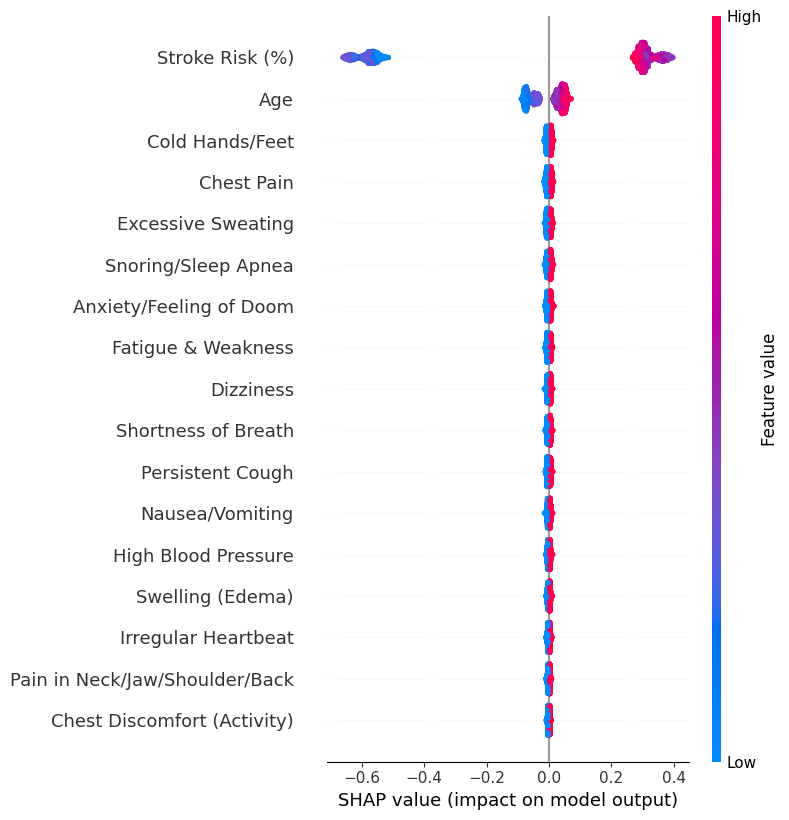

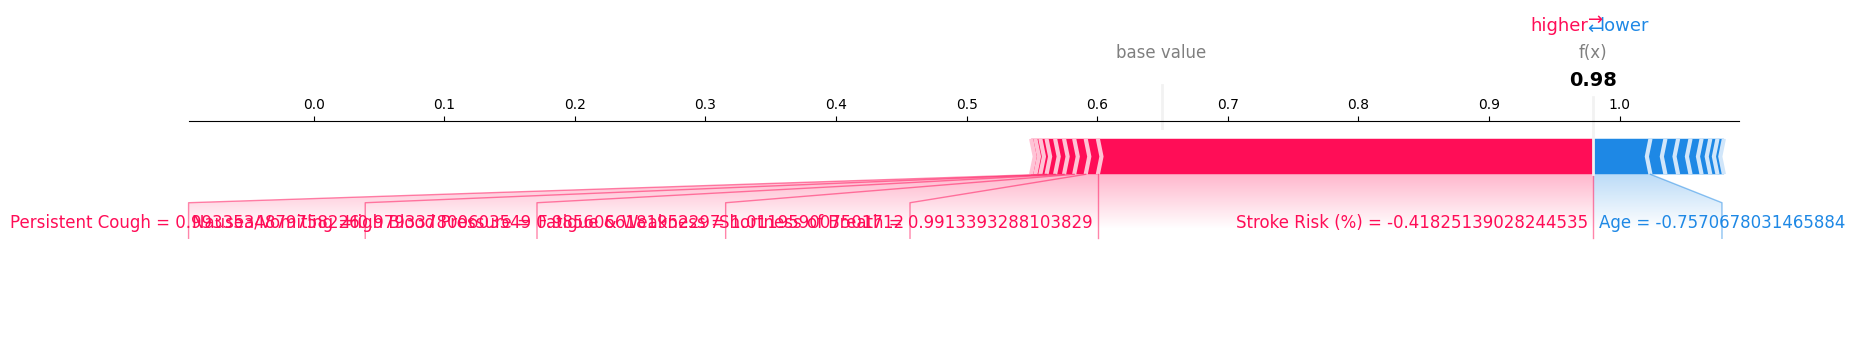

[('Fatigue & Weakness > 1.00', 0.14010800790434108), ('Snoring/Sleep Apnea <= -1.00', 0.026640671073427564), ('-1.00 < Pain in Neck/Jaw/Shoulder/Back <= 1.00', -0.02348880778267344), ('-1.00 < Irregular Heartbeat <= 1.00', 0.02134101431458789), ('-0.86 < Age <= -0.00', 0.018438082472589216), ('-1.00 < High Blood Pressure <= 1.00', 0.017911419265405723), ('-1.01 < Excessive Sweating <= 0.99', -0.009213968673540157), ('-1.00 < Swelling (Edema) <= 1.00', -0.008918331322616857), ('Anxiety/Feeling of Doom <= -1.00', -0.00848711890115113), ('-1.00 < Persistent Cough <= 1.00', 0.008224181752023406)]


In [85]:
import shap
import lime
import lime.lime_tabular
import matplotlib.pyplot as plt
import numpy as np

# Example: Explain Random Forest model predictions

# Use original unscaled X_test (if you want to explain on original features)
# Otherwise explain on scaled data accordingly

# For SHAP (TreeExplainer works well with tree-based models)
explainer_shap = shap.TreeExplainer(rf)  # rf is your trained RandomForestClassifier
shap_values = explainer_shap.shap_values(X_test)  # X_test or X_test_scaled as per your model input

# Summary plot of SHAP values for class 1 (positive class)
shap.summary_plot(shap_values[1], X_test, feature_names=X_test.columns)

# Individual prediction explanation with SHAP for first sample
shap.force_plot(explainer_shap.expected_value[1], shap_values[1][0], X_test.iloc[0], matplotlib=True)

# -------------------

# For LIME
# Initialize LIME explainer for tabular data
explainer_lime = lime.lime_tabular.LimeTabularExplainer(
    training_data=np.array(X_train),
    feature_names=X_train.columns,
    class_names=['Class 0', 'Class 1'],
    mode='classification'
)

# Explain the prediction for a single instance (e.g. first test sample)
i = 0
exp = explainer_lime.explain_instance(
    data_row=X_test.iloc[i],
    predict_fn=rf.predict_proba
)

# Show explanation as list of feature contributions
print(exp.as_list())

# Plot LIME explanation
exp.show_in_notebook(show_table=True)

# Or save the plot as html
exp.save_to_file('lime_explanation.html')


** Optional: Save SHAP Summary as Image**

What this script will do:
Take your trained models (Logistic Regression, RF, SVM, GBM, XGBoost, MLP, Naive Bayes)

Generate global SHAP summary plots per model (feature importance overview)

Generate local SHAP force plot for one example prediction per model

Generate LIME explanation for the same example prediction per model

Save plots as HTML (for LIME) and PNG (for SHAP summary) to your working directory

Important:
Tree models (RF, GBM, XGBoost) → use shap.TreeExplainer

Linear/logistic, MLP, Naive Bayes → use shap.KernelExplainer (slower)

SVM → also use shap.KernelExplainer

LIME works the same for all

In [100]:
import shap
import lime
import lime.lime_tabular
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd


In [101]:
# Step 2: Train or Load Your Models (including SVM with probability=True)
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.svm import SVC
from sklearn.naive_bayes import GaussianNB
from sklearn.neural_network import MLPClassifier
import xgboost as xgb

# Ensure data is preprocessed and split
# X_train, X_test, y_train, y_test

logreg = LogisticRegression()
rf = RandomForestClassifier(n_estimators=100, random_state=42)
svm = SVC(kernel='linear', probability=True, random_state=42)  # ✅ FIXED
gbm = GradientBoostingClassifier(n_estimators=100, random_state=42)
xgb_model = xgb.XGBClassifier(use_label_encoder=False, eval_metric='logloss', random_state=42)
mlp = MLPClassifier(random_state=42)
nb = GaussianNB()

# Train all models
models = {
    'Logistic Regression': logreg,
    'Random Forest': rf,
    'SVM': svm,
    'Gradient Boosting': gbm,
    'XGBoost': xgb_model,
    'Multilayer Perceptron': mlp,
    'Naive Bayes': nb
}

for name, model in models.items():
    model.fit(X_train, y_train)


In [102]:
#Step 3: Set Up SHAP and LIME Explainers
# Choose 1 sample for local explanation
example_idx = 0

# LIME Explainer
lime_explainer = lime.lime_tabular.LimeTabularExplainer(
    training_data=np.array(X_train),
    feature_names=X_train.columns,
    class_names=['Class 0', 'Class 1'],
    mode='classification'
)

# SHAP background sample for KernelExplainer
background = shap.sample(X_train, 100)



=== Explaining model: Logistic Regression ===


  0%|          | 0/100 [00:00<?, ?it/s]

Generating SHAP force plot for instance 0...


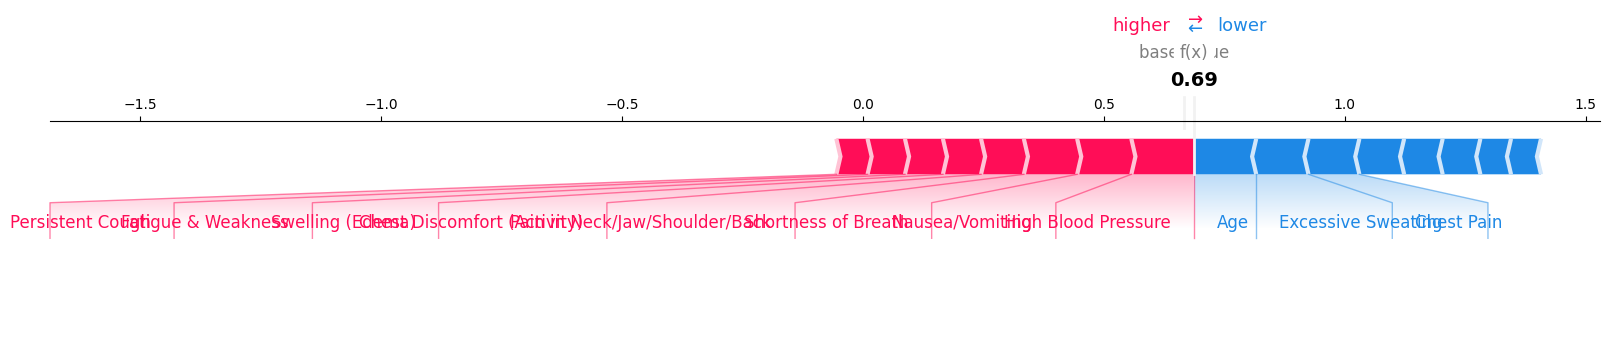

Generating LIME explanation for instance 0...
[('Fatigue & Weakness > 1.00', -0.18681430825437056), ('-0.76 < Stroke Risk (%) <= -0.00', 0.0593684238640894), ('-1.00 < Persistent Cough <= 1.00', 0.027309425106879802), ('-1.01 < Dizziness <= 0.99', 0.025993624729338742), ('-1.00 < Pain in Neck/Jaw/Shoulder/Back <= 1.00', 0.024472943064675234), ('-1.00 < Cold Hands/Feet <= 1.00', 0.021926114880974554), ('-0.99 < Shortness of Breath <= 1.01', 0.02155814254510713), ('Anxiety/Feeling of Doom <= -1.00', -0.01986640358455169), ('-1.01 < Excessive Sweating <= 0.99', 0.01842749199476995), ('-1.00 < Chest Pain <= 1.00', 0.01824702207686708)]
✅ Completed explanations for Logistic Regression

=== Explaining model: Random Forest ===
Generating SHAP force plot for instance 0...


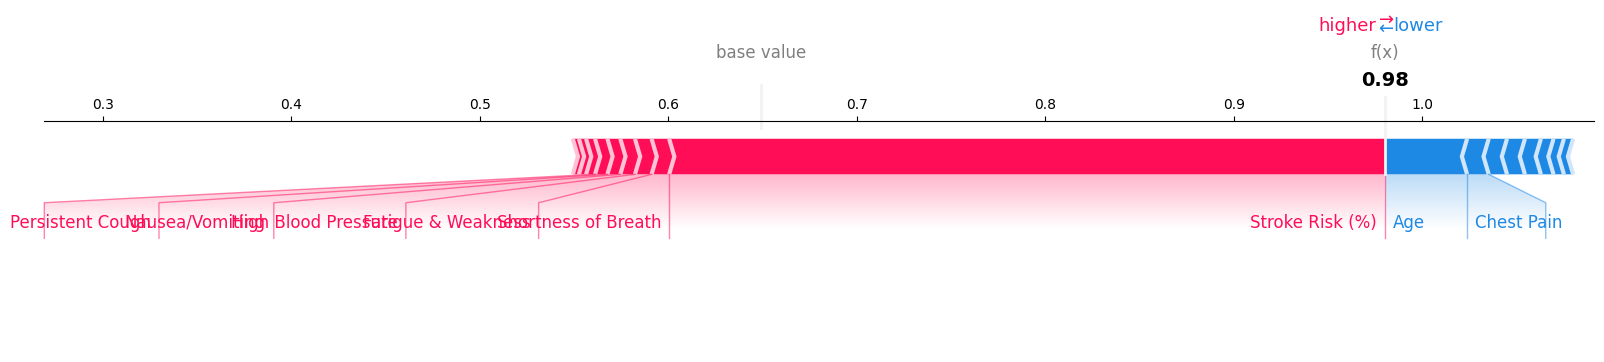

Generating LIME explanation for instance 0...
[('Fatigue & Weakness > 1.00', 0.16319495502588924), ('-1.00 < Nausea/Vomiting <= 1.00', 0.027522361004115575), ('-0.86 < Age <= -0.00', -0.019035923729818934), ('Snoring/Sleep Apnea <= -1.00', -0.01901320132621751), ('-1.00 < High Blood Pressure <= 1.00', -0.01666093372706422), ('-1.00 < Chest Pain <= 1.00', -0.016293075020461362), ('-1.01 < Excessive Sweating <= 0.99', 0.015276987287289191), ('-1.00 < Pain in Neck/Jaw/Shoulder/Back <= 1.00', 0.01361209426952115), ('-1.00 < Irregular Heartbeat <= 1.00', -0.006711108672501676), ('-0.76 < Stroke Risk (%) <= -0.00', -0.006505054718144424)]
✅ Completed explanations for Random Forest

=== Explaining model: SVM ===


  0%|          | 0/100 [00:00<?, ?it/s]

Generating SHAP force plot for instance 0...


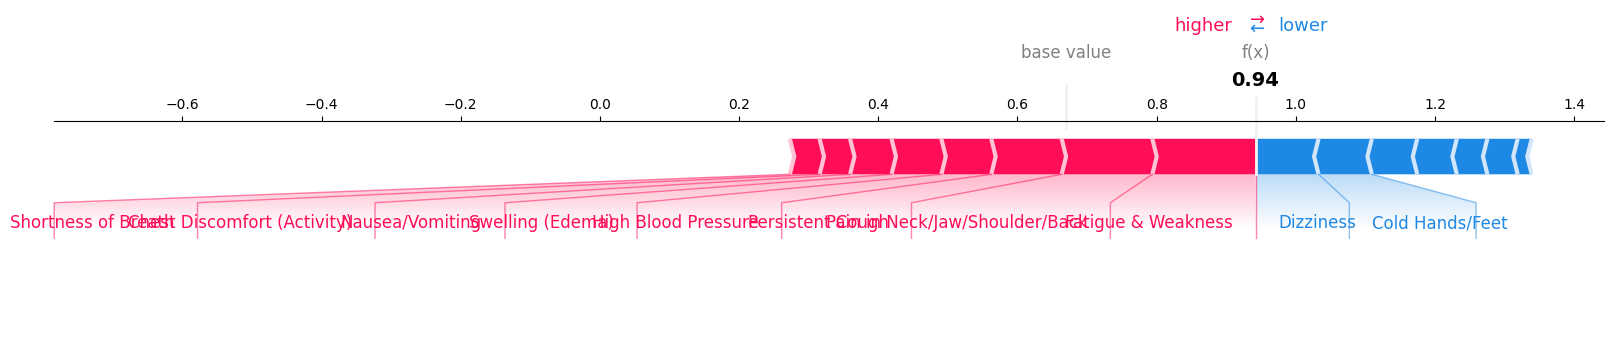

Generating LIME explanation for instance 0...
[('-0.76 < Stroke Risk (%) <= -0.00', 0.060992236605227686), ('Fatigue & Weakness > 1.00', -0.06091093837771008), ('-0.86 < Age <= -0.00', 0.026283785578224136), ('-1.00 < Irregular Heartbeat <= 1.00', 0.02507686806629985), ('-1.01 < Excessive Sweating <= 0.99', 0.023948411461526212), ('-0.99 < Shortness of Breath <= 1.01', 0.01884732123567142), ('-1.00 < Cold Hands/Feet <= 1.00', 0.01815999861856167), ('Snoring/Sleep Apnea <= -1.00', -0.017566913898036576), ('-1.01 < Dizziness <= 0.99', 0.014346316535770662), ('-1.00 < Pain in Neck/Jaw/Shoulder/Back <= 1.00', 0.013716386381018153)]
✅ Completed explanations for SVM

=== Explaining model: Gradient Boosting ===
Generating SHAP force plot for instance 0...


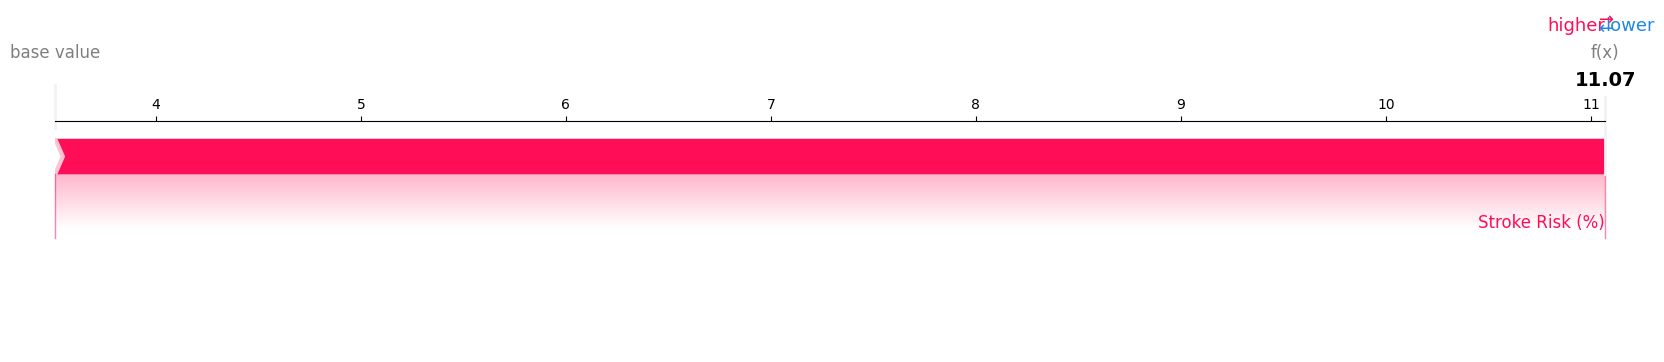

Generating LIME explanation for instance 0...
[('Fatigue & Weakness > 1.00', 0.15253247722331043), ('Anxiety/Feeling of Doom <= -1.00', -0.0367498377153254), ('-1.00 < Pain in Neck/Jaw/Shoulder/Back <= 1.00', 0.03538802198779818), ('-1.00 < High Blood Pressure <= 1.00', 0.026733014368439903), ('-1.00 < Persistent Cough <= 1.00', 0.024190043925223347), ('-1.01 < Excessive Sweating <= 0.99', -0.019598777206307656), ('-0.99 < Shortness of Breath <= 1.01', 0.013991565154826649), ('-1.01 < Dizziness <= 0.99', 0.013467521926904294), ('-1.00 < Cold Hands/Feet <= 1.00', -0.01031238669072149), ('-1.00 < Nausea/Vomiting <= 1.00', 0.009625093018110664)]
✅ Completed explanations for Gradient Boosting

=== Explaining model: XGBoost ===
Generating SHAP force plot for instance 0...


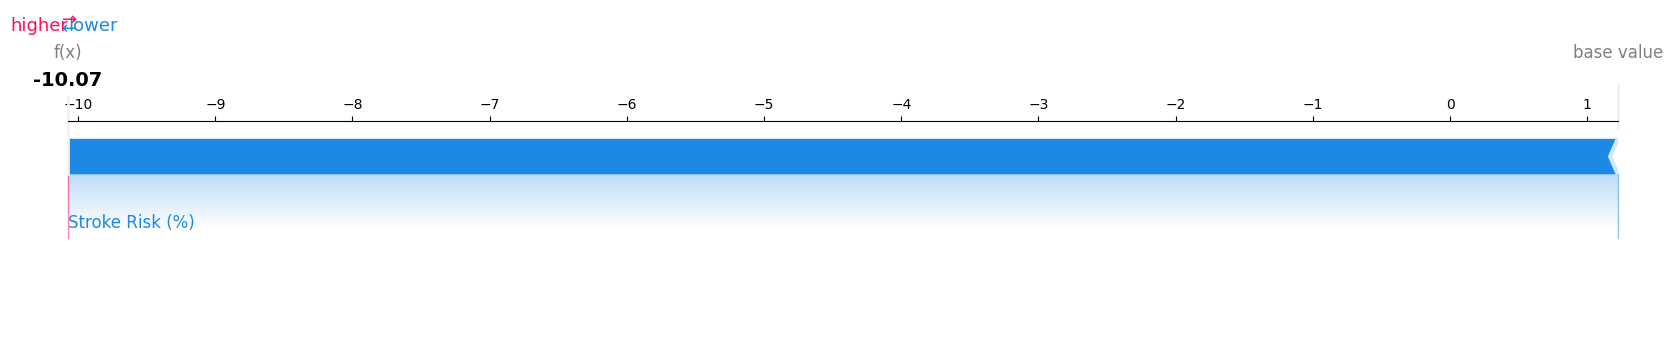

Generating LIME explanation for instance 0...
[('Fatigue & Weakness > 1.00', -0.32066506102162423), ('-0.76 < Stroke Risk (%) <= -0.00', -0.034906444315563744), ('-1.00 < Irregular Heartbeat <= 1.00', 0.034008905601388924), ('-0.99 < Shortness of Breath <= 1.01', 0.023160988180010604), ('-0.86 < Age <= -0.00', 0.022863817659104314), ('Anxiety/Feeling of Doom <= -1.00', 0.022305301554176364), ('-1.00 < Swelling (Edema) <= 1.00', -0.016980874580521027), ('-1.00 < Chest Discomfort (Activity) <= 1.00', -0.016750849165023132), ('-1.01 < Excessive Sweating <= 0.99', -0.015813888199209387), ('-1.00 < High Blood Pressure <= 1.00', -0.015646068399283782)]
✅ Completed explanations for XGBoost

=== Explaining model: Multilayer Perceptron ===


  0%|          | 0/100 [00:00<?, ?it/s]

Generating SHAP force plot for instance 0...


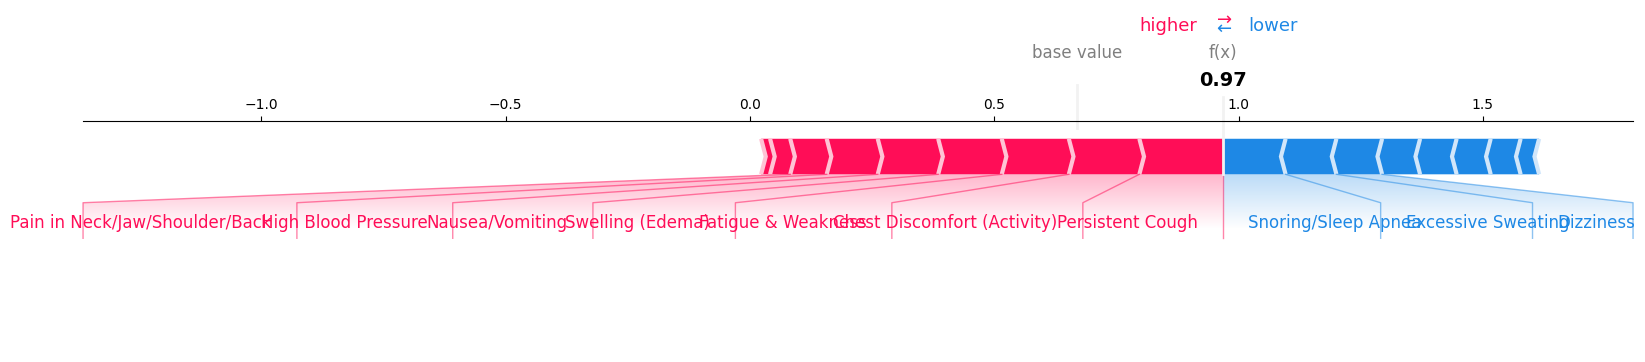

Generating LIME explanation for instance 0...
[('-0.76 < Stroke Risk (%) <= -0.00', 0.09270561102082901), ('Fatigue & Weakness > 1.00', -0.05200117210138154), ('-1.00 < Pain in Neck/Jaw/Shoulder/Back <= 1.00', 0.02998506554093403), ('-1.00 < Persistent Cough <= 1.00', 0.029195540552879016), ('-1.00 < High Blood Pressure <= 1.00', 0.029145547024542688), ('-1.00 < Irregular Heartbeat <= 1.00', 0.02880134031895665), ('Snoring/Sleep Apnea <= -1.00', -0.028729065914046923), ('-1.00 < Swelling (Edema) <= 1.00', 0.025512708148990423), ('-1.00 < Chest Discomfort (Activity) <= 1.00', 0.02420407839003533), ('-1.01 < Excessive Sweating <= 0.99', 0.023069275883864645)]
✅ Completed explanations for Multilayer Perceptron

=== Explaining model: Naive Bayes ===


  0%|          | 0/100 [00:00<?, ?it/s]

Generating SHAP force plot for instance 0...


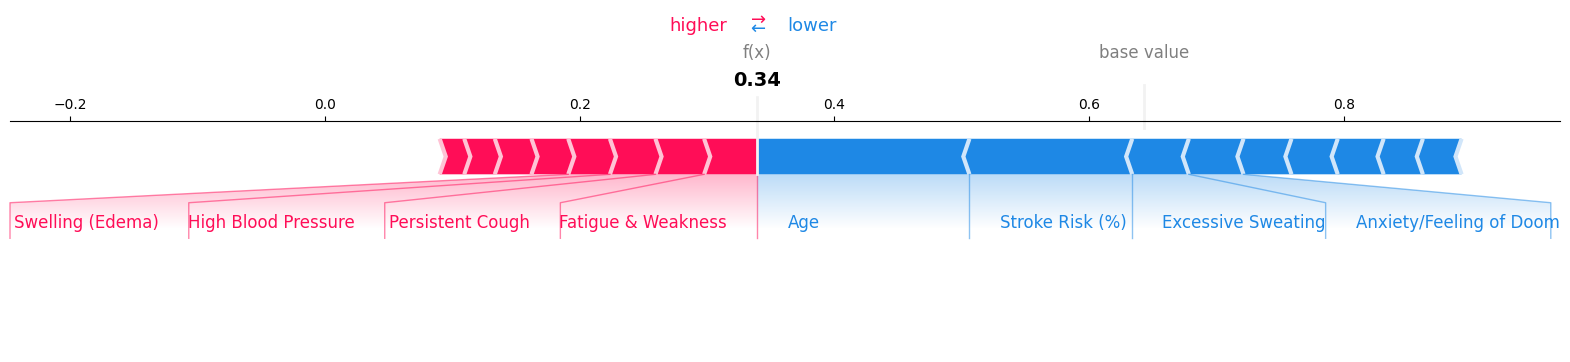

Generating LIME explanation for instance 0...
[('Fatigue & Weakness > 1.00', -0.25722088979722174), ('-0.86 < Age <= -0.00', -0.0777490242786449), ('-0.76 < Stroke Risk (%) <= -0.00', 0.06443597600356209), ('-0.99 < Shortness of Breath <= 1.01', 0.031222966695407296), ('-1.00 < Nausea/Vomiting <= 1.00', 0.02342037391241263), ('-1.00 < Persistent Cough <= 1.00', 0.021391962914629862), ('-1.00 < Irregular Heartbeat <= 1.00', 0.020068331962225544), ('Anxiety/Feeling of Doom <= -1.00', -0.019841764699977785), ('-1.00 < Cold Hands/Feet <= 1.00', 0.018841695992476867), ('-1.01 < Excessive Sweating <= 0.99', 0.017102111277709324)]
✅ Completed explanations for Naive Bayes


In [103]:
# Step 4: SHAP + LIME Explanations (Fixed)
for model_name, model in models.items():
    print(f"\n=== Explaining model: {model_name} ===")

    # Choose explainer
    if model_name in ['Random Forest', 'Gradient Boosting', 'XGBoost']:
        explainer = shap.TreeExplainer(model)
        shap_values = explainer.shap_values(X_test)
        shap_vals_to_use = shap_values[1] if isinstance(shap_values, list) else shap_values
    else:
        explainer = shap.KernelExplainer(model.predict_proba, background)
        shap_values = explainer.shap_values(X_test.iloc[:100], nsamples=100)
        shap_vals_to_use = shap_values[1] if isinstance(shap_values, list) and len(shap_values) > 1 else shap_values

    # Summary Plot (Global)
    plt.figure()
    shap.summary_plot(
        shap_vals_to_use,
        X_test.iloc[:shap_vals_to_use.shape[0]],
        feature_names=X_test.columns,
        show=False
    )
    plt.title(f"SHAP Summary - {model_name}")
    plt.savefig(f"shap_summary_{model_name.replace(' ', '_')}.png")
    plt.close()

    # Force Plot (Local)
    if example_idx < shap_vals_to_use.shape[0]:
        print(f"Generating SHAP force plot for instance {example_idx}...")

        base_value = explainer.expected_value
        if isinstance(base_value, (list, np.ndarray)) and len(base_value) > 1:
            base_value = base_value[1]  # positive class

        shap.plots.force(
            base_value,
            shap_vals_to_use[example_idx],
            feature_names=X_test.columns,
            matplotlib=True,
            show=True
        )

    # LIME Explanation
    if example_idx < X_test.shape[0]:
        print(f"Generating LIME explanation for instance {example_idx}...")
        lime_exp = lime_explainer.explain_instance(
            data_row=X_test.iloc[example_idx],
            predict_fn=model.predict_proba,
            num_features=10
        )
        print(lime_exp.as_list())
        lime_exp.save_to_file(f'lime_explanation_{model_name.replace(" ", "_")}.html')

    print(f"✅ Completed explanations for {model_name}")


<div style="border: 10px solid black; background-color:#ffd700; color:black; text-align:left; padding: 30px; font-size:40px; font-family:Verdana, sans-serif;">
<b>9. Model Evaluation & Metrics</b>
</div>

In [89]:
# 🔹 Best Performers: Random Forest, Gradient Boosting, and XGBoost all achieved perfect accuracy, 
#    indicating robust performance across all metrics.

# 🔹 Room for Improvement: SVM, while still achieving good accuracy, showed some misclassifications 
#    (false positives and false negatives), suggesting it might benefit from further optimization. 
#    Models like Random Forest, Gradient Boosting, and XGBoost seem to be the best choices for this dataset.

<div style="border: 10px solid black; background-color:#ffd700; color:black; text-align:left; padding: 30px; font-size:40px; font-family:Verdana, sans-serif;">
<b>10. Feature Importance</b>
</div>

In [91]:
def plot_feature_importance(model, X, feature_names=None):
    """Plot the feature importance for tree-based models."""
    if hasattr(model, 'feature_importances_'): 
        importance = model.feature_importances_

        if feature_names is None:
            if hasattr(X, 'columns'):
                feature_names = X.columns
            else:
                feature_names = [f"Feature {i}" for i in range(X.shape[1])]
        
        indices = np.argsort(importance)[::-1]
        
        plt.figure(figsize=(10, 6))
        plt.barh(range(X.shape[1]), importance[indices], align="center")
        plt.yticks(range(X.shape[1]), [feature_names[i] for i in indices])
        plt.title("Feature Importance for Random Forest")
        plt.xlabel('Importance')
        plt.show()

In [92]:
def feature_importance_rf(X_train, y_train, feature_names=None, random_state=42):
    """Train Random Forest model and plot feature importance."""
    rf_model = RandomForestClassifier(random_state=random_state)
    rf_model.fit(X_train, y_train)
    plot_feature_importance(rf_model, X_train, feature_names)

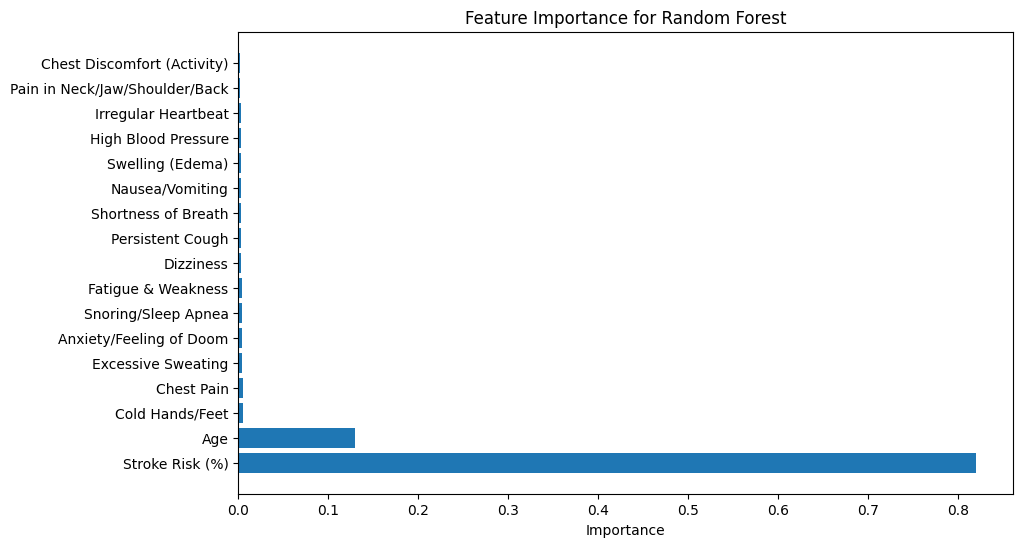

In [93]:
feature_importance_rf(X_train, y_train, df.columns)

<div style="border: 10px solid black; background-color:#ffd700; color:red; text-align:left; padding: 30px; font-size:40px; font-family:Verdana, sans-serif;">
<b>Thank you for reading! If you found this notebook helpful, please consider giving it an upvote. Your support is appreciated! 😊</b>
</div>